<a href="https://colab.research.google.com/github/Ivan-Mayabi/SemProject_MLEngine/blob/feat%2FspatialLag/Regression_Base_(GWR%2C_OSM%2C_Spatial_Lag).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Part 1: Data Entry

In [ ]:
%pip install matplotlib pandas numpy seaborn

In [ ]:
# Import the data set from google drive
from google.colab import drive

drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [ ]:
# Find the data within the path

path = '/content/drive/MyDrive/Colab Notebooks/Year 3 - Artificial Intelligence/Deliverable 1/US_Accidents_March23/US_Accidents_March23.csv'
print(path)

/content/drive/MyDrive/Colab Notebooks/Year 3 - Artificial Intelligence/Deliverable 1/US_Accidents_March23/US_Accidents_March23.csv


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv(path,nrows=2500000)

In [ ]:
# Get the actual data needed

Head = df.head(15)
Tail = df.tail(20)
df_sample = pd.concat([Head,Tail],ignore_index=True)

df_sample

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-1,Source2,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Night
1,A-2,Source2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Day
2,A-3,Source2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,NaN,NaN,0.01,...,False,False,False,False,True,False,Night,Night,Day,Day
3,A-4,Source2,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Day,Day,Day
4,A-5,Source2,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,NaN,NaN,0.01,...,False,False,False,False,True,False,Day,Day,Day,Day
5,A-6,Source2,3,2016-02-08 07:44:26,2016-02-08 08:14:26,40.100590,-82.925194,NaN,NaN,0.01,...,False,False,False,False,False,False,Day,Day,Day,Day
6,A-7,Source2,2,2016-02-08 07:59:35,2016-02-08 08:29:35,39.758274,-84.230507,NaN,NaN,0.00,...,False,False,False,False,False,False,Day,Day,Day,Day
7,A-8,Source2,3,2016-02-08 07:59:58,2016-02-08 08:29:58,39.770382,-84.194901,NaN,NaN,0.01,...,False,False,False,False,False,False,Day,Day,Day,Day
8,A-9,Source2,2,2016-02-08 08:00:40,2016-02-08 08:30:40,39.778061,-84.172005,NaN,NaN,0.00,...,False,False,False,False,False,False,Day,Day,Day,Day
9,A-10,Source2,3,2016-02-08 08:10:04,2016-02-08 08:40:04,40.100590,-82.925194,NaN,NaN,0.01,...,False,False,False,False,False,False,Day,Day,Day,Day


 ### Pre-processing

In [ ]:
# Shape of the data

df.shape

(2500000, 46)

In [ ]:
# Show which columns have null data
df.isnull().sum()

,0
ID,0
Source,0
Severity,0
Start_Time,0
End_Time,0
Start_Lat,0
Start_Lng,0
End_Lat,2500000
End_Lng,2500000
Distance(mi),0


### Part 3: EDA

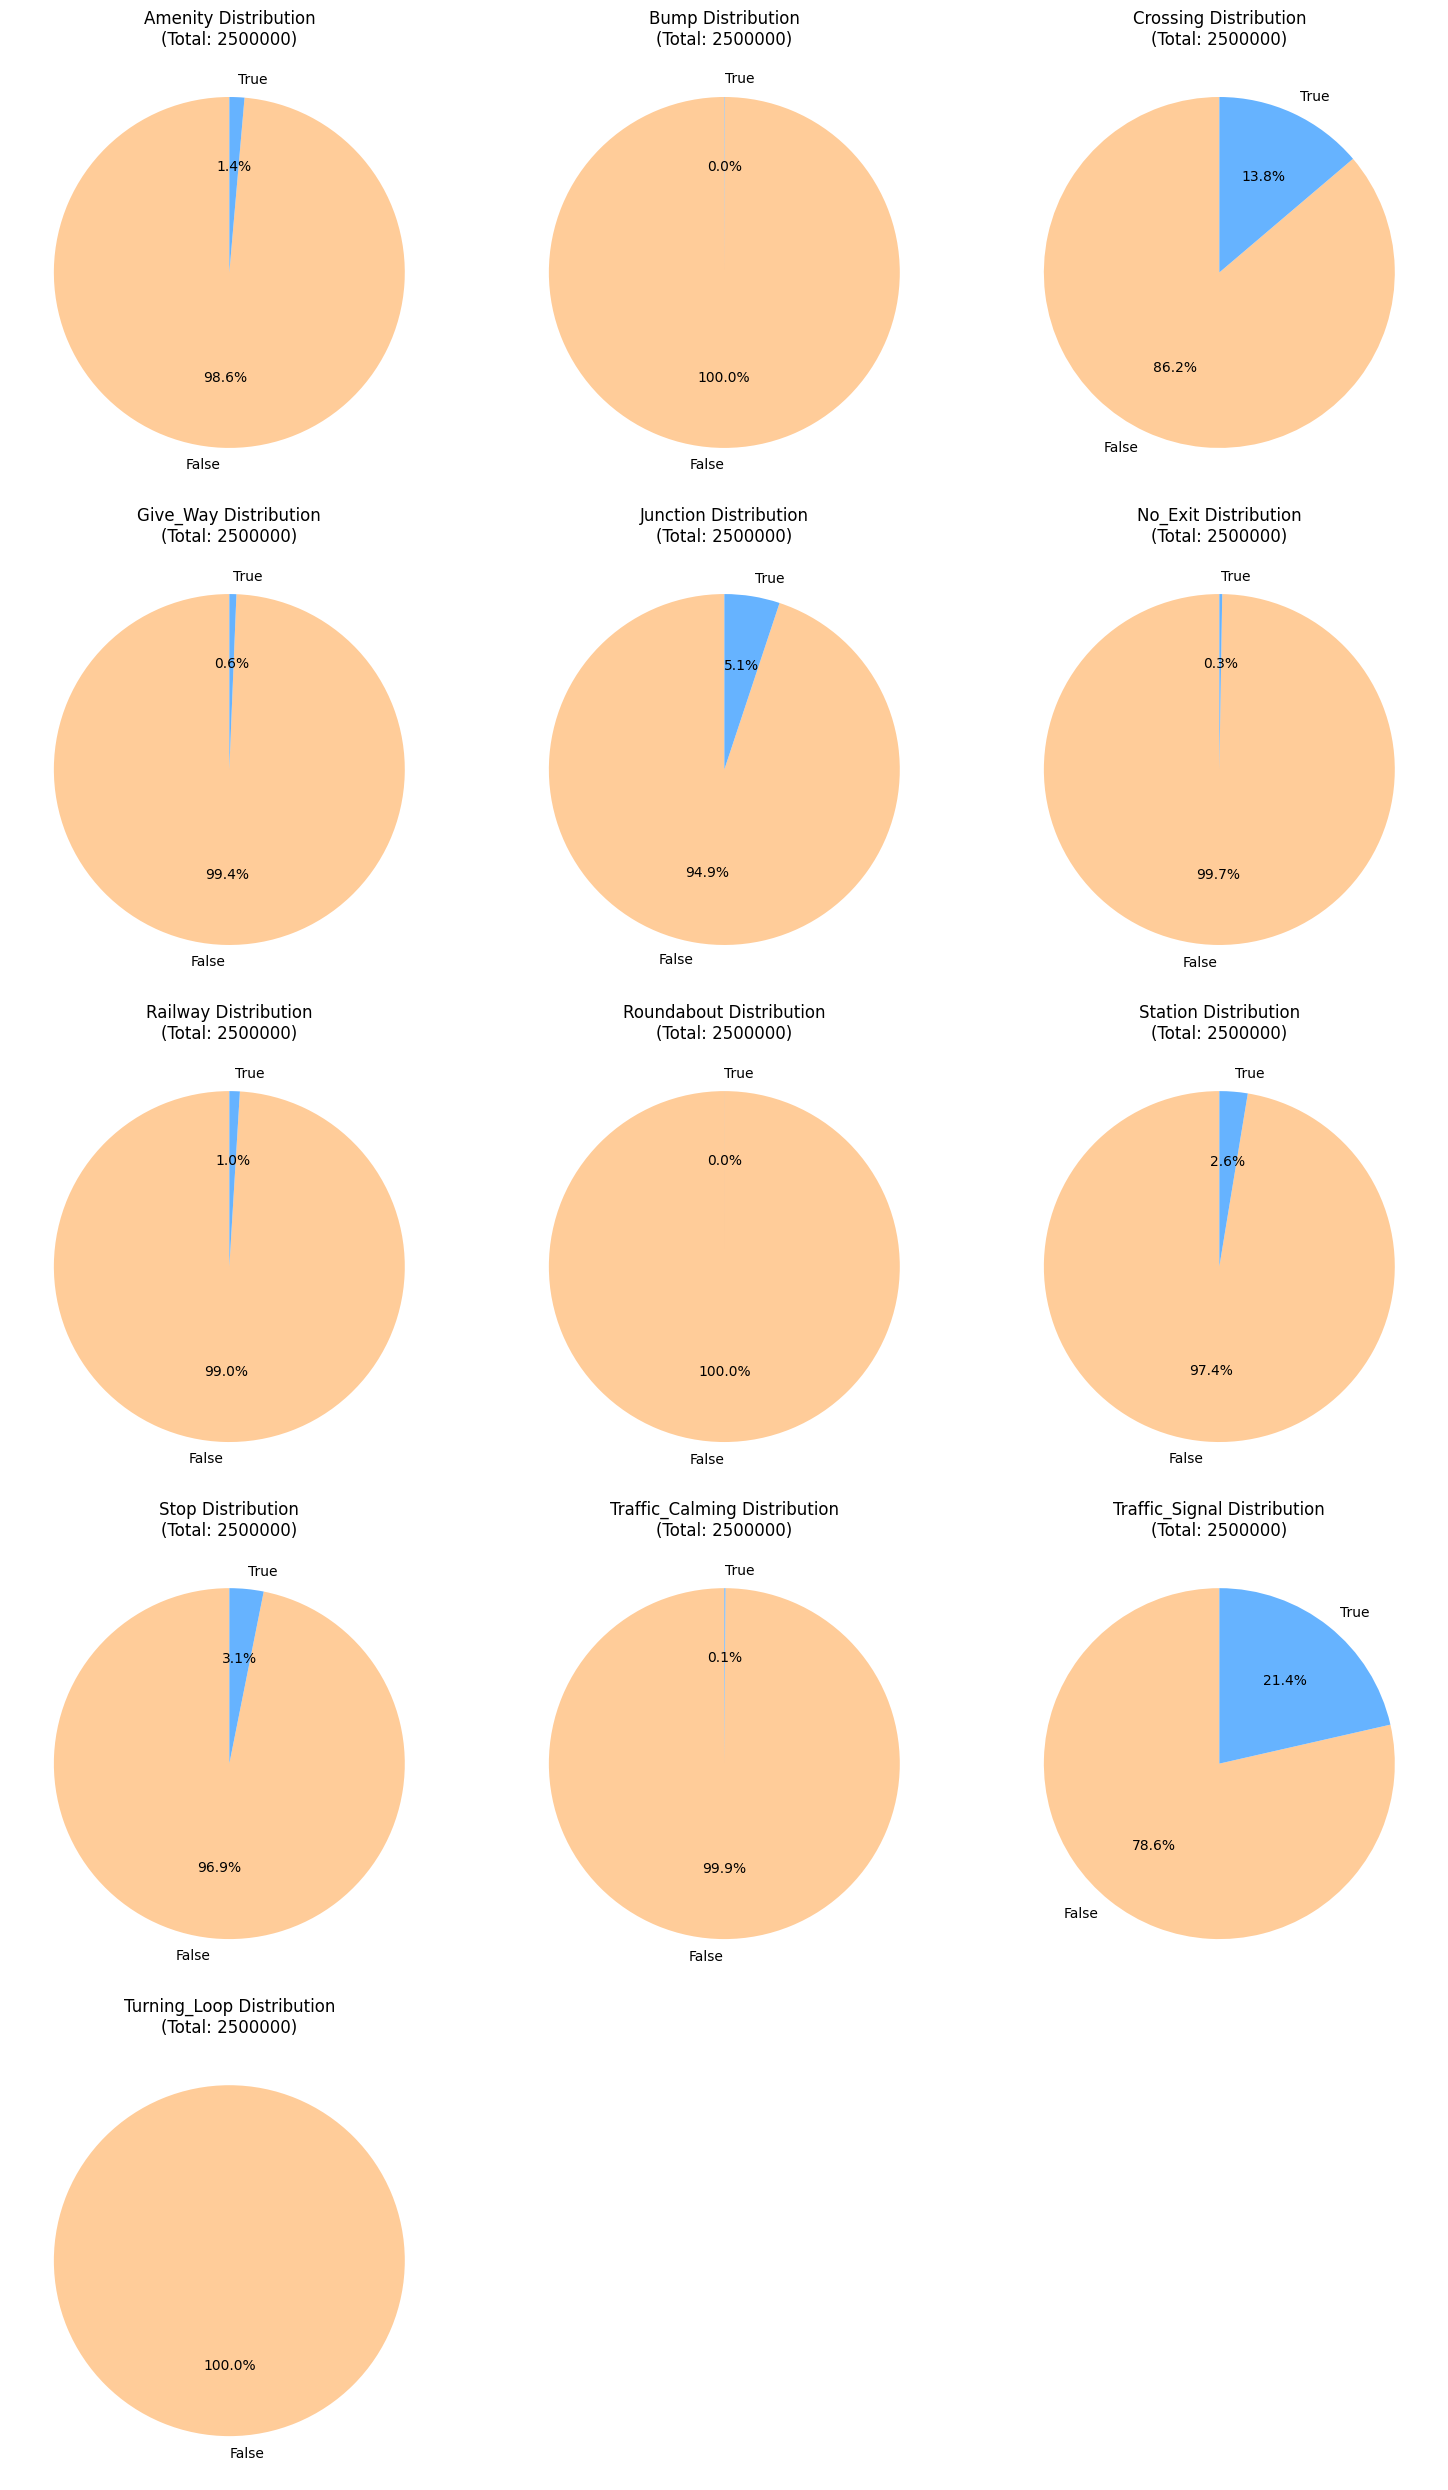

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# List of boolean columns representing road features
road_features = [
    'Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction',
    'No_Exit', 'Railway', 'Roundabout', 'Station', 'Stop',
    'Traffic_Calming', 'Traffic_Signal', 'Turning_Loop'
]

# Filter to features that are actually in our DataFrame
available_features = [col for col in road_features if col in df.columns]

if available_features:
    # Define the number of plots and grid layout
    n_features = len(available_features)
    cols = 3
    rows = (n_features + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
    axes = axes.flatten()

    for i, feature in enumerate(available_features):
        # Count True vs False occurrences for the current feature
        counts = df[feature].value_counts()

        # Ensure we represent True and False explicitly in the labels
        labels = [f'{val}' for val in counts.index]

        # Plotting the pie chart showing True vs False distribution
        axes[i].pie(
            counts,
            labels=labels,
            autopct='%1.1f%%',
            startangle=90,
            colors=['#ffcc99', '#66b3ff']  # Warm and cool colors for comparison
        )
        axes[i].set_title(f'{feature} Distribution\n(Total: {len(df)})')

    # Hide any unused subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()
else:
    print("No matching road feature columns found in the dataset.")

In [ ]:
eda_df = df.copy()

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

eda_df['Start_Time'] = pd.to_datetime(eda_df['Start_Time'], format='mixed', errors='coerce')
eda_df['End_Time'] = pd.to_datetime(eda_df['End_Time'], format='mixed', errors='coerce')

eda_df['hour'] = eda_df['Start_Time'].dt.hour
eda_df['day_name'] = eda_df['Start_Time'].dt.day_name()
eda_df['month'] = eda_df['Start_Time'].dt.month
eda_df['year'] = eda_df['Start_Time'].dt.year
eda_df['is_weekend'] = eda_df['Start_Time'].dt.dayofweek >= 5
eda_df['serious'] = eda_df['Severity'] >= 3
eda_df['duration_min'] = (eda_df['End_Time'] - eda_df['Start_Time']).dt.total_seconds() / 60

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

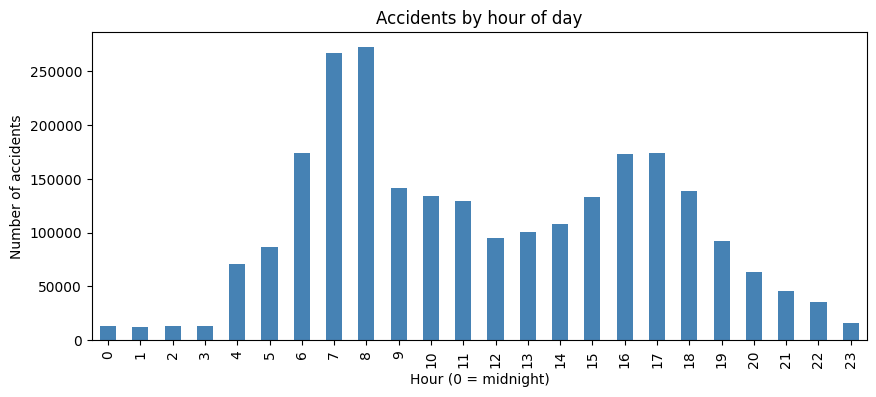

In [ ]:
eda_df['hour'].value_counts().sort_index().plot(kind='bar', figsize=(10, 4), color='steelblue')
plt.title('Accidents by hour of day')
plt.xlabel('Hour (0 = midnight)')
plt.ylabel('Number of accidents')
plt.show()

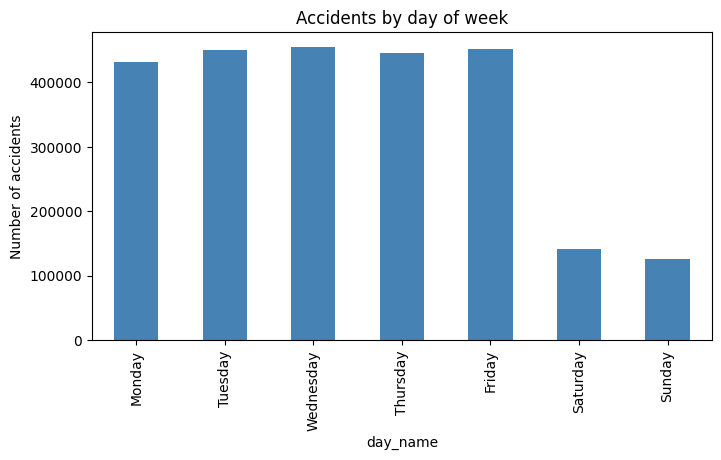

Average accidents per day:
 is_weekend
Weekday    1617.2
Weekend     494.8
Name: count, dtype: float64


In [ ]:
eda_df['day_name'].value_counts().reindex(day_order).plot(kind='bar', figsize=(8, 4), color='steelblue')
plt.title('Accidents by day of week')
plt.ylabel('Number of accidents')
plt.show()

daily = (eda_df.groupby(eda_df['Start_Time'].dt.date)
               .agg(count=('ID', 'count'), is_weekend=('is_weekend', 'first')))
avg = daily.groupby('is_weekend')['count'].mean().rename({False: 'Weekday', True: 'Weekend'})
print("Average accidents per day:\n", avg.round(1))

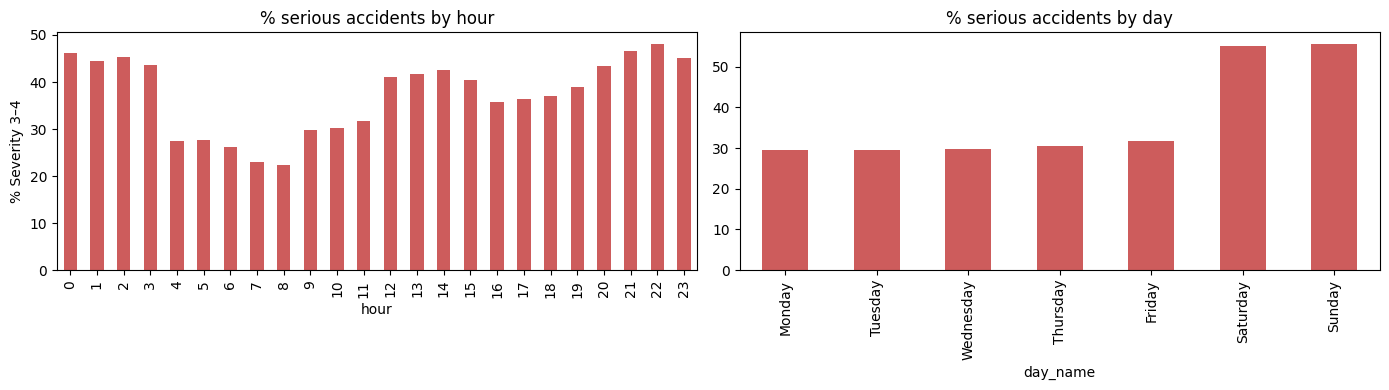

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

(eda_df.groupby('hour')['serious'].mean() * 100).plot(kind='bar', ax=axes[0], color='indianred')
axes[0].set_title('% serious accidents by hour')
axes[0].set_ylabel('% Severity 3–4')

(eda_df.groupby('day_name')['serious'].mean().reindex(day_order) * 100).plot(kind='bar', ax=axes[1], color='indianred')
axes[1].set_title('% serious accidents by day')

plt.tight_layout()
plt.show()

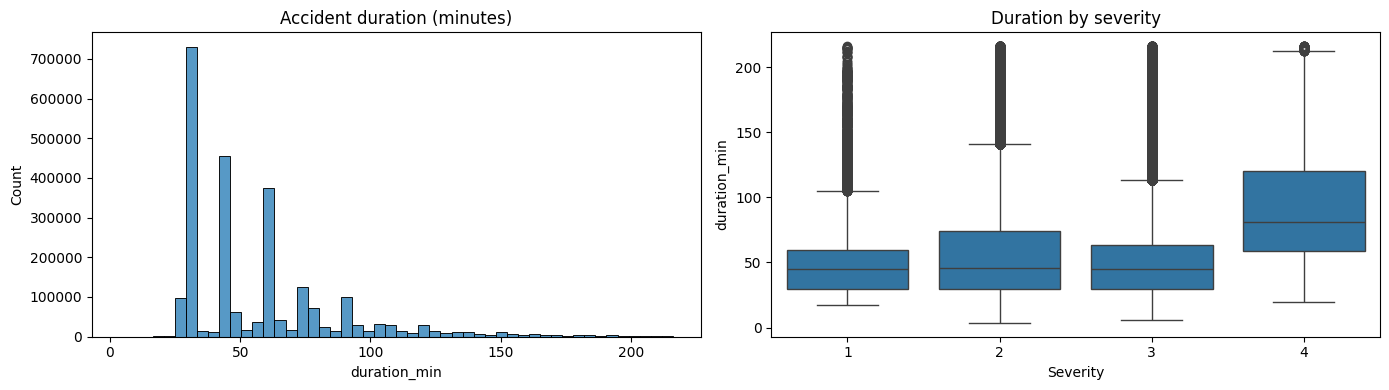

Median duration (min) by severity:
 Severity
1    44.9
2    45.9
3    44.7
4    81.0
Name: duration_min, dtype: float64


In [ ]:
dur = eda_df[eda_df['duration_min'] > 0]
dur = dur[dur['duration_min'] <= dur['duration_min'].quantile(0.99)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(dur['duration_min'], bins=50, ax=axes[0])
axes[0].set_title('Accident duration (minutes)')

sns.boxplot(data=dur, x='Severity', y='duration_min', ax=axes[1])
axes[1].set_title('Duration by severity')
plt.tight_layout()
plt.show()

print("Median duration (min) by severity:\n", dur.groupby('Severity')['duration_min'].median().round(1))

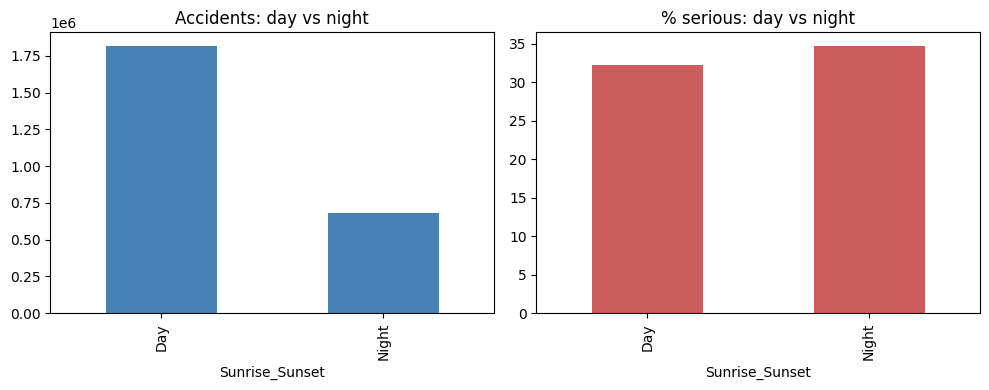

In [ ]:
light = eda_df.dropna(subset=['Sunrise_Sunset'])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
light['Sunrise_Sunset'].value_counts().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Accidents: day vs night')

(light.groupby('Sunrise_Sunset')['serious'].mean() * 100).plot(kind='bar', ax=axes[1], color='indianred')
axes[1].set_title('% serious: day vs night')
plt.tight_layout()
plt.show()

where do accidents happen and what is nearby

In [ ]:
#setting up cell
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# The True/False road-feature columns in this dataset
road_features = ['Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit',
                 'Railway', 'Roundabout', 'Station', 'Stop', 'Traffic_Calming',
                 'Traffic_Signal', 'Turning_Loop']

# Quick check: these should all be 'bool' for the code to work
print(df[road_features].dtypes.value_counts())

# A temporary True/False Series marking serious accidents (Severity 3 or 4).
# It's stored separately, NOT added to df.
serious = df['Severity'] >= 3

bool    13
Name: count, dtype: int64


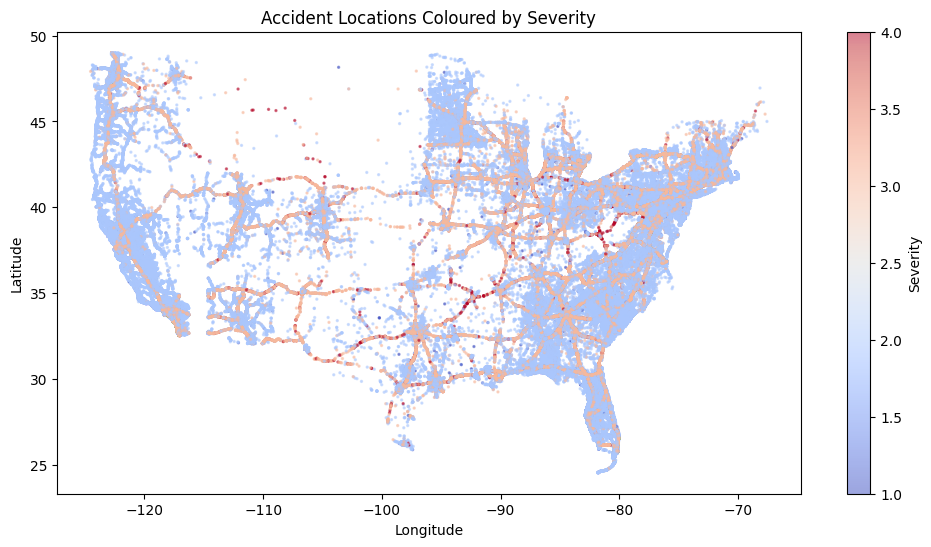

In [ ]:
##Where accidents happen, scatterplot
# Longitude (east-west) goes on the x-axis and latitude (north-south) on the y-axis,
# so the plot reads like a map. Each dot is one accident, coloured by severity.
plt.figure(figsize=(12, 6))
points = plt.scatter(df['Start_Lng'], df['Start_Lat'],
                     c=df['Severity'], cmap='coolwarm', s=2, alpha=0.5)
plt.colorbar(points, label='Severity')
plt.title('Accident Locations Coloured by Severity')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

                 Accidents where True  % of all accidents
Traffic_Signal                 535860               21.43
Crossing                       344621               13.78
Junction                       127441                5.10
Stop                            78523                3.14
Station                         64886                2.60
Amenity                         34549                1.38
Railway                         24013                0.96
Give_Way                        16168                0.65
No_Exit                          6615                0.26
Traffic_Calming                  2524                0.10
Bump                              935                0.04
Roundabout                         91                0.00
Turning_Loop                        0                0.00


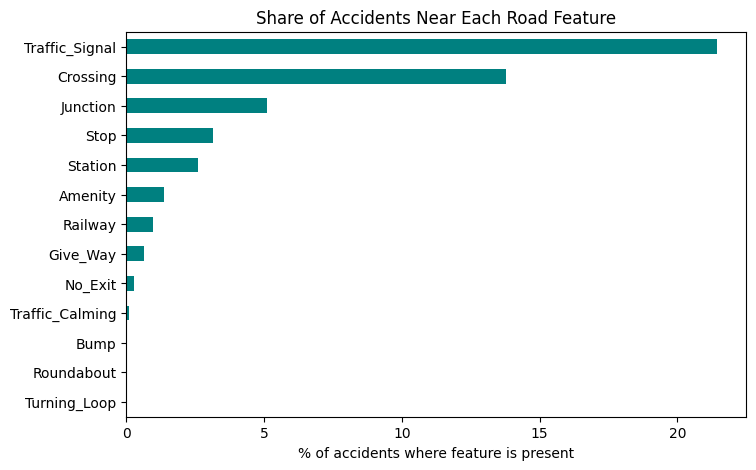

In [ ]:
#how common is each road feature
# Summing a True/False column counts the Trues
feature_counts = df[road_features].sum().sort_values(ascending=False)
feature_pct = feature_counts / len(df) * 100

summary = pd.DataFrame({'Accidents where True': feature_counts,
                        '% of all accidents': feature_pct.round(2)})
print(summary)

plt.figure(figsize=(8, 5))
feature_pct.sort_values().plot(kind='barh', color='teal')
plt.title('Share of Accidents Near Each Road Feature')
plt.xlabel('% of accidents where feature is present')
plt.show()

                 Accidents when True  % serious when True  \
Feature                                                     
Traffic_Signal                535860                  8.6   
Crossing                      344621                  7.1   
Junction                      127441                 54.4   
Stop                           78523                  5.4   
Station                        64886                  9.9   
Amenity                        34549                  6.3   
Railway                        24013                 22.1   
Give_Way                       16168                 16.9   
No_Exit                         6615                 14.8   
Traffic_Calming                 2524                 26.2   
Bump                             935                 25.8   
Roundabout                        91                  3.3   
Turning_Loop                       0                  NaN   

                 % serious when False  Enough data?  
Feature                       

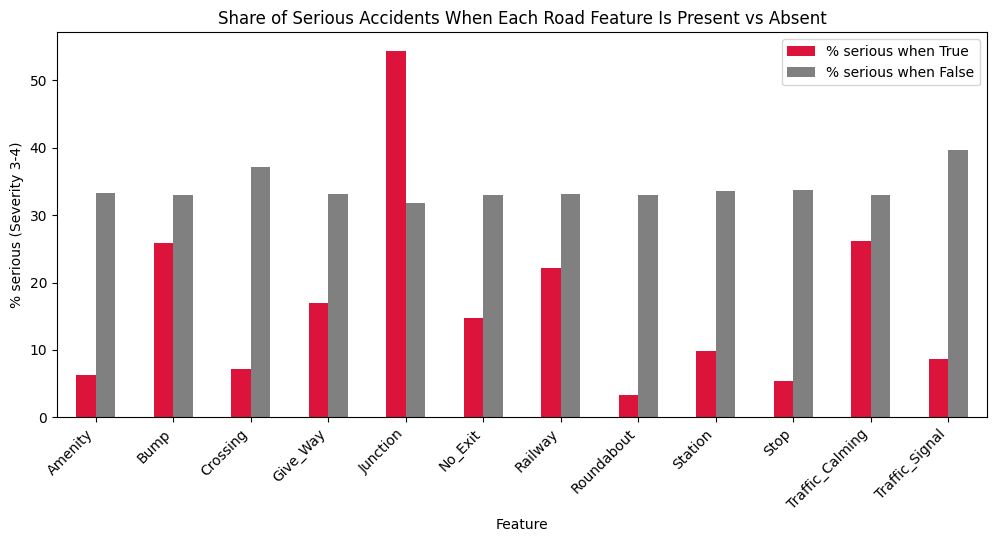

In [ ]:
##serious-accident percentage
# For each feature, split accidents into two piles (feature present / absent)
# and find what % of each pile was serious.
min_true = 30   # fewer True accidents than this = too few to trust (a judgement call)
rows = []

for feature in road_features:
    n_true = int(df[feature].sum())
    pct = serious.groupby(df[feature]).mean() * 100   # % serious in each pile
    rows.append({
        'Feature': feature,
        'Accidents when True': n_true,
        '% serious when True': round(pct.get(True, np.nan), 1),
        '% serious when False': round(pct.get(False, np.nan), 1),
    })

comparison = pd.DataFrame(rows).set_index('Feature')
comparison['Enough data?'] = comparison['Accidents when True'] >= min_true
print(comparison.sort_values('Accidents when True', ascending=False))

# Features with too few True values to draw conclusions from
low_data = comparison[~comparison['Enough data?']].index.tolist()
print('\nToo few cases to trust:', low_data)

# Chart only the features with enough data
trusted = comparison[comparison['Enough data?']]
trusted[['% serious when True', '% serious when False']].plot(
    kind='bar', figsize=(12, 5), color=['crimson', 'grey'])
plt.title('Share of Serious Accidents When Each Road Feature Is Present vs Absent')
plt.ylabel('% serious (Severity 3-4)')
plt.xticks(rotation=45, ha='right')
plt.show()

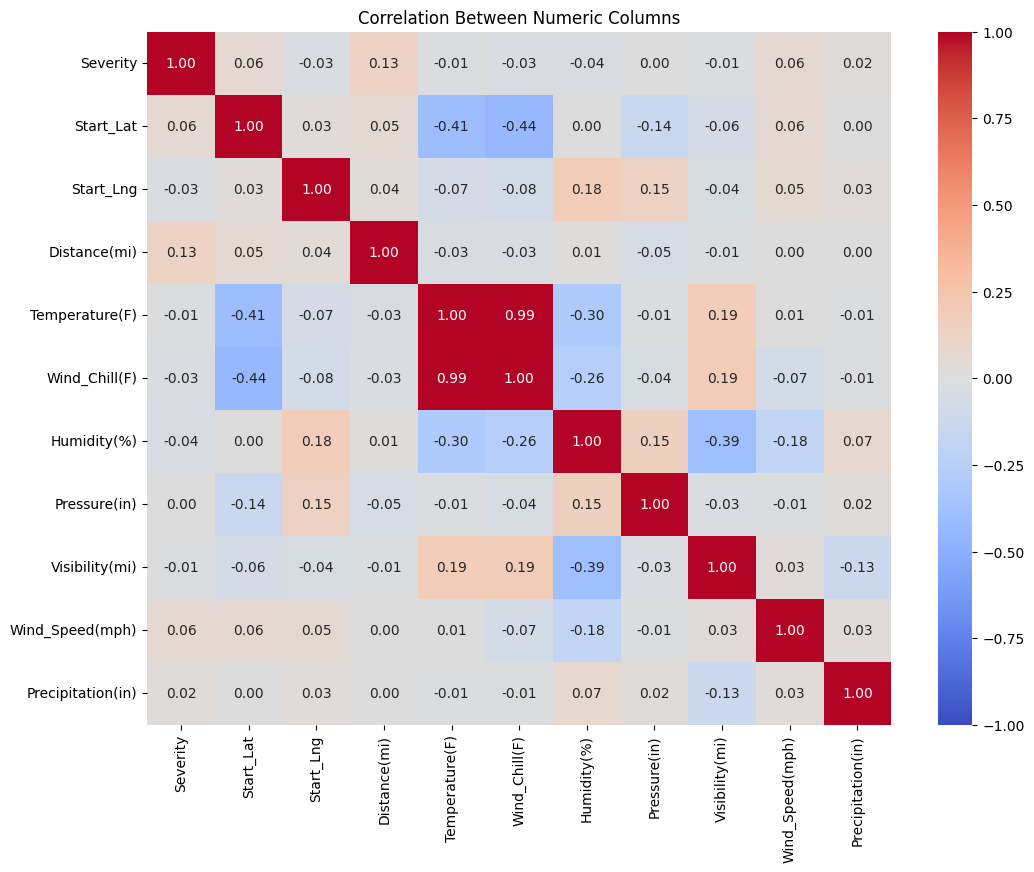

Pairs with correlation of 0.7 or stronger:
Temperature(F)  Wind_Chill(F)    0.99
dtype: float64

Top 10 pairs overall:
Temperature(F)  Wind_Chill(F)      0.99
Start_Lat       Wind_Chill(F)     -0.44
                Temperature(F)    -0.41
Humidity(%)     Visibility(mi)    -0.39
Temperature(F)  Humidity(%)       -0.30
Wind_Chill(F)   Humidity(%)       -0.26
                Visibility(mi)     0.19
Temperature(F)  Visibility(mi)     0.19
Humidity(%)     Wind_Speed(mph)   -0.18
Start_Lng       Humidity(%)        0.18
dtype: float64


In [ ]:
##CORRELATION HEAT MAP OF NUMERICAL VALUES
# Temporary copy of just the numeric columns
numeric = df.select_dtypes(include='number')

# Completely empty columns (End_Lat, End_Lng) can't be correlated, so we
# leave them out of THIS chart only. df itself is not changed.
numeric = numeric.loc[:, numeric.notna().any()]

corr = numeric.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1)
plt.title('Correlation Between Numeric Columns')
plt.show()

##Highly correlated pairs
# Keep only the upper triangle of the matrix so each pair appears once
# (Temperature-Wind_Chill, not also Wind_Chill-Temperature)
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))

# Turn the grid into a list of pairs, strongest first (ignoring +/- sign)
pairs = upper.stack().sort_values(key=abs, ascending=False)

threshold = 0.7
print(f'Pairs with correlation of {threshold} or stronger:')
print(pairs[pairs.abs() >= threshold].round(2))

print('\nTop 10 pairs overall:')
print(pairs.head(10).round(2))

Traffic_Signal      -0.264
Crossing            -0.214
Distance(mi)         0.129
Junction             0.103
Stop                -0.102
Station             -0.078
Amenity             -0.065
Wind_Speed(mph)      0.059
Start_Lat            0.056
Humidity(%)         -0.038
Wind_Chill(F)       -0.029
Give_Way            -0.027
Start_Lng           -0.027
Railway             -0.023
No_Exit             -0.020
Precipitation(in)    0.019
Visibility(mi)      -0.012
Temperature(F)      -0.011
Traffic_Calming     -0.005
Pressure(in)         0.003
Roundabout          -0.003
Bump                -0.003
dtype: float64


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


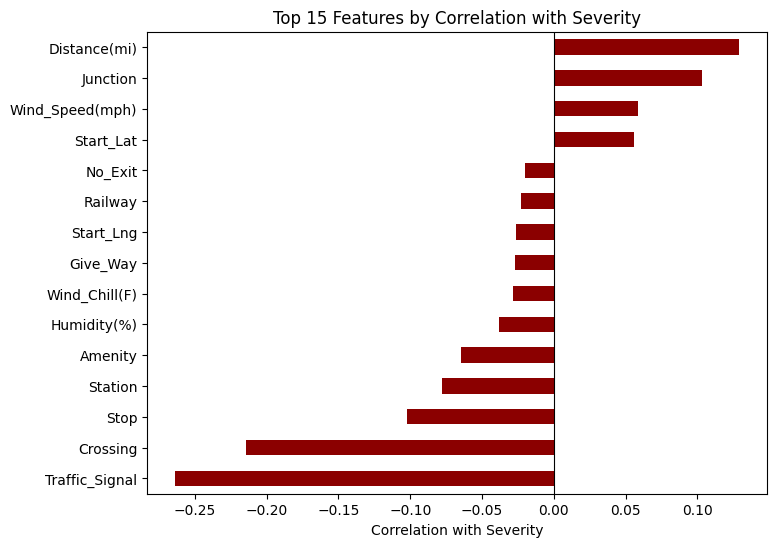

In [ ]:
##Which features are mostly linked to serverity
# Numeric columns plus road features, as a temporary float copy
# (True becomes 1, False becomes 0) so they can all be correlated.
cols = [c for c in numeric.columns if c != 'Severity' and c in df.columns] + road_features
link = df[cols].astype(float).corrwith(df['Severity'])

# Constant columns (e.g. Turning_Loop if it's always False) give NaN,
# so leave them out of this result
link = link.dropna().sort_values(key=abs, ascending=False)
print(link.round(3))

plt.figure(figsize=(8, 6))
link.head(15).sort_values().plot(kind='barh', color='darkred')
plt.title('Top 15 Features by Correlation with Severity')
plt.xlabel('Correlation with Severity')
plt.axvline(0, color='black', linewidth=0.8)
plt.show()

### Part 3: Data Cleaning

In [ ]:
df.isnull().sum()


,0
ID,0
Source,0
Severity,0
Start_Time,0
End_Time,0
Start_Lat,0
Start_Lng,0
End_Lat,2500000
End_Lng,2500000
Distance(mi),0


#### Part 3.1 Remove Null columns

Remove End_Lat and End_Lng => Have all their data missing

In [ ]:
df = df.drop(columns=["End_Lat"])
df = df.drop(columns=["End_Lng"])
df.shape

(2500000, 44)

Remove Wind_Chill => Too many fields missing

* In the original dataset, Only 26% of the dataset has this value missing
* However, google searches have shown that this is a derived field that is only calculated when temparature is below 10'C

In [ ]:
df = df.drop(columns=["Wind_Chill(F)"])
df.shape

(2500000, 43)

Remove all other rows that contain less than 1000 null values => Too few to impact training

In [ ]:
df = df.dropna(subset=["Street","City","Zipcode","Timezone","Airport_Code","Weather_Timestamp","Temperature(F)","Humidity(%)","Pressure(in)","Visibility(mi)","Wind_Direction","Weather_Condition","Sunrise_Sunset","Civil_Twilight","Nautical_Twilight","Astronomical_Twilight"],how='any')
df.isnull().sum()

,0
ID,0
Source,0
Severity,0
Start_Time,0
End_Time,0
Start_Lat,0
Start_Lng,0
Distance(mi),0
Description,4
Street,0


Fill in Wind Speed values with the averages of those columns

Wind Speed:
* Too many to drop (About 10% of the truncated dataset)

Precipitaiton:
* One of the most important weather conditions
* Also disproportionately allocated on this truncated data frame.
* Only 29% missing on the original dataset

In [ ]:
# df["Wind_Speed(mph)"] = df["Wind_Speed(mph)"].fillna(df["Wind_Speed(mph)"].mean())
# df["Precipitation(in)"] = df["Precipitation(in)"].fillna(df["Precipitation(in)"].mean())

# Gonna drop them to experiment on the impact it has
df = df.drop(columns=["Precipitation(in)","Wind_Speed(mph)"])
df.isnull().sum()

,0
ID,0
Source,0
Severity,0
Start_Time,0
End_Time,0
Start_Lat,0
Start_Lng,0
Distance(mi),0
Description,4
Street,0


### Part 3.2: Remove columns deemed unnecessary

#### Part 3.2.1: Remove Identification Columns

Remove ID and source columns since they don't provide any useful information to training
<br>
Remove Country column since every single column there has a value is US

In [ ]:
df = df.drop(columns=["Source"])
df = df.drop(columns=["Country"])
df.shape

(2426698, 39)

#### Part 2.2.2: Remove Columns Only known after accident has occurred

After consultation with Claude: Can drop certain columns that are known after the accident takes place:

* End_Time
* Distance(mi)
* Description

In [ ]:
df = df.drop(columns=["End_Time","Distance(mi)","Description"])

df.shape

(2426698, 36)

### Part 3.2.3: Remove Columns Specific to only the US

After further consultation: Can drop columns that contain data that cannot be ported over to Kenyan Situations:
* County
* Street
* Zipcode
* City
* Timezone
* Airport_Code

In [ ]:
df = df.drop(columns=["County","Zipcode","City","Timezone","Street","Airport_Code"])

df.shape

(2426698, 30)

### Part 3.3: Converting True and False into 1s and 0s

Perform Feature Engineering (One Hot Encoding) on the many true/false fields

From the EDA, we will create variables surrounding the relationship of data:

* Major Road Features:
  * Junctions
  * Traffic Lights / Signals
  * Crossings / Zebra Crossings
* Minor Road Features:All other road features
* Weather: All other weather features (No encoding done here)
* Day_Time: All daylight columns


In [ ]:
major_columns = ["Junction","Traffic_Signal","Crossing"]

df[major_columns] = df[major_columns].replace({'False':0,"True":1})

In [ ]:
minor_columns = ["Amenity","Bump","Give_Way","No_Exit","Railway","Roundabout","Station","Stop","Traffic_Calming","Turning_Loop"]

df[minor_columns] = df[minor_columns].replace({'False':0,"True":1})

In [ ]:
day_times = ["Sunrise_Sunset","Civil_Twilight","Nautical_Twilight","Astronomical_Twilight"]

df[day_times] = df[day_times].replace({'Night':0,"Day":1})

/tmp/ipykernel_3177/3317706886.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[day_times] = df[day_times].replace({'Night':0,"Day":1})


#### Part 3.4: Converting Start_Time Column into multiple date time fields

To derive further value from the data , encoded the date and time fields

In [ ]:
df["Start_Time"] = pd.to_datetime(df["Start_Time"],format="mixed")
df["Start_Time"]

,Start_Time
0,2016-02-08 05:46:00
1,2016-02-08 06:07:59
2,2016-02-08 06:49:27
3,2016-02-08 07:23:34
4,2016-02-08 07:39:07
...,...
2499995,2018-10-10 14:51:15
2499996,2018-10-10 15:34:27
2499997,2018-10-10 15:39:00
2499998,2018-10-10 15:50:46


In [ ]:
# Make the time to be in minutes
df["Minutes"] = df["Start_Time"].dt.hour * 60 + df["Start_Time"].dt.minute
df["Minutes"]

,Minutes
0,346
1,367
2,409
3,443
4,459
...,...
2499995,891
2499996,934
2499997,939
2499998,950


In [ ]:
# Get the day of the week and the month
df["Day_of_Week"]=df["Start_Time"].dt.dayofweek
df["Month"]=df["Start_Time"].dt.month
start_day_info = ["Minutes","Day_of_Week","Month"]
df[start_day_info]

,Minutes,Day_of_Week,Month
0,346,0,2
1,367,0,2
2,409,0,2
3,443,0,2
4,459,0,2
...,...,...,...
2499995,891,2,10
2499996,934,2,10
2499997,939,2,10
2499998,950,2,10


Shape of the data after cleaning

In [ ]:
df.shape

(2426698, 33)

## Part 4: Route risk level — Low / Medium / High

**Idea:** every row in the raw data is one accident, so a model can't learn "accident vs no accident" directly.
We reshape the data so that **one row = one area at one time slot**, count the accidents there (including slots with **zero** accidents), and turn that into a risk level.

The model then learns *why* some areas/times are riskier (road features + time), so the app can predict risk for any route segment — including Kenyan roads with no history in this dataset.

- **Problem type:** classification (Low / Medium / High)
- **Base model:** Random Forest
- **Validation:** stratified 5-fold cross-validation
- **Weather is left out on purpose:** weather is only recorded when an accident happened, so zero-accident rows have no weather → it would leak the answer.

### 4.2 Build the area × time-slot table
- **Area:** grid squares of 0.05° (≈5 km)
- **Time slot:** time band (night / morning / afternoon / evening) × weekday or weekend
- Counts are turned into a **rate per day**, because there are 5 weekdays but only 2 weekend days a week — otherwise weekdays would always look riskier.

In [ ]:
GRID = 0.05   # grid size in degrees (~5 km). Try 0.02 or 0.1 and compare.
Grid_round_off = 1

# agg_df = raw.copy()
"""
  Creates the cells (area groupings)
"""
# df['cell'] = ((df['Start_Lat'] // GRID).astype(int).astype(str) + '_' +
#                   (df['Start_Lng'] // GRID).astype(int).astype(str))
df["cell"] = df["Start_Lat"].round(Grid_round_off).astype(str) + "_" + df["Start_Lng"].round(Grid_round_off).astype(str)

hour = df['Start_Time'].dt.hour

"""
  Creates time bands based on time of day
  Creates a weekend column that tracks if weekend or not
"""
# df['time_band'] = pd.cut(hour, bins=[-1, 5, 11, 16, 23],
#                              labels=['night', 'morning', 'afternoon', 'evening'])
# df['is_weekend'] = (df['Start_Time'].dt.dayofweek >= 5).astype(int)

""""
  Groups the dataset based on cell, time of day and if is a weekend
  Generates accident counts based on the groupings
"""
# Count accidents in every cell x slot, INCLUDING zero-accident slots
counts = (df.groupby(['cell'], observed=False)
                .size().reset_index(name='accident_count'))

"""
  Creates a map of all the days that accidents have been recorded across
"""
# Number of weekday / weekend days in the period -> accidents per day
# all_days = pd.Series(pd.date_range(df['Start_Time'].min().normalize(),
#                                    df['Start_Time'].max().normalize()))
"""
  Counts the number of days that were weekdays and weekends
  Gets a rate per day based of if it was a weekend or weekday
"""
# print(all_days)
# n_days = {0: int((all_days.dt.dayofweek < 5).sum()), 1: int((all_days.dt.dayofweek >= 5).sum())}
# counts['rate_per_day'] = counts['accident_count'] / counts['is_weekend'].map(n_days)
# print(counts)

print('Number of grid cells:', df['cell'].nunique())
print('Rows in new table (cells x 8 slots):', len(counts))
# print('Weekday / weekend days in period:', n_days)
print('\nShare of slots with zero accidents: {:.1f}%'.format((counts['accident_count'] == 0).mean() * 100))

counts

Number of grid cells: 21485
Rows in new table (cells x 8 slots): 21485

Share of slots with zero accidents: 0.0%


,cell,accident_count
0,24.6_-81.6,4
1,24.6_-81.7,14
2,24.6_-81.8,19
3,24.7_-81.0,14
4,24.7_-81.1,43
...,...,...
21480,49.0_-122.4,5
21481,49.0_-122.5,9
21482,49.0_-122.6,1
21483,49.0_-122.7,25


### 4.3 Road-feature and weather profile of each area
For each cell: the **share** of its accidents that were near each road feature, plus the average weather recorded there.

We use the share rather than "was there ever one" (yes/no), because a cell with many accidents is more likely to have *at least one* near a junction just by chance. That would make busy cells look like junction cells and inflate the results.

In [ ]:
road = ['Junction', 'Traffic_Signal', 'Crossing', 'Stop', 'Station', 'Amenity', 'Railway']
weather = ['Temperature(F)', 'Humidity(%)', 'Pressure(in)','Visibility(mi)']
"""
  A bit shaky on this
  If we are running with average of accidents, shouldn't we also group by time and weekend as previous
  - Got claude assistance = Can work on weather but not on roads(Road features stay the same despite weather)
  - Implemented fix = Only gave 0.02 improvement
"""
cell_profile = (df.groupby('cell')[road].mean()
                      .add_suffix('_share').reset_index())
weather_profile = (df.groupby('cell')[weather].mean()
                      .add_suffix('_share').reset_index())
table = counts.merge(cell_profile, on='cell')
table = table.merge(weather_profile,on='cell')
table.head()

,cell,accident_count,Junction_share,Traffic_Signal_share,Crossing_share,Stop_share,Station_share,Amenity_share,Railway_share,Temperature(F)_share,Humidity(%)_share,Pressure(in)_share,Visibility(mi)_share
0,24.6_-81.6,4,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0,84.750000,66.000000,30.005000,10.000000
1,24.6_-81.7,14,0.0,0.142857,0.142857,0.0,0.000000,0.000000,0.0,77.864286,75.857143,30.072857,9.642857
2,24.6_-81.8,19,0.0,0.421053,0.421053,0.0,0.052632,0.105263,0.0,80.263158,70.631579,30.042632,9.736842
3,24.7_-81.0,14,0.0,0.428571,0.000000,0.0,0.071429,0.000000,0.0,79.214286,72.357143,30.023571,9.857143
4,24.7_-81.1,43,0.0,0.069767,0.255814,0.0,0.186047,0.023256,0.0,80.302326,73.023256,30.024884,9.790698


Visualisation of the accident count based on cell.

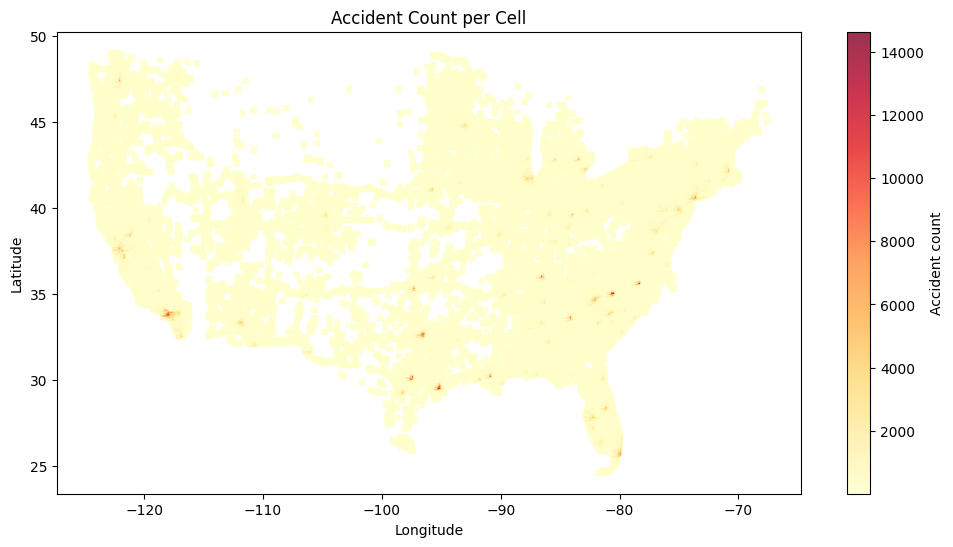

In [ ]:
## Where accidents happen, by grid cell
# Split "24.555_-81.78" into latitude and longitude numbers
table[['lat', 'lng']] = table['cell'].str.split('_', expand=True).astype(float)

# Each square is one cell, coloured by how many accidents it had
plt.figure(figsize=(12, 6))
points = plt.scatter(table['lng'], table['lat'],
                     c=table['accident_count'], cmap='YlOrRd',
                     s=15, marker='s', alpha=0.8)
plt.colorbar(points, label='Accident count')
plt.title('Accident Count per Cell')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

### 4.6 Prepare features and split
Only features the app can actually get: **time** (phone clock) and **road features** (map data such as OpenStreetMap).

In [ ]:
from sklearn.model_selection import train_test_split

"""
  Create the train and test split
"""
# print(table)
# model_df = pd.get_dummies(table, columns=['time_band'], dtype=int) #Binary Encoding
model_df = table
# print(model_df)
feature_cols = [c for c in model_df.columns if c.endswith('_share') or c.startswith('time_band_')]

X = model_df[feature_cols]
# X = X.drop(columns="Visibility(mi)_share")
y = model_df['accident_count']
groups = model_df['cell']      # used later for the 'new area' check

"""
  Stratify to make data split sort of evenly between the train and test

"""
X_train, X_test, y_train, y_test, g_train, g_test = train_test_split(
    X, y, groups, test_size=0.2, random_state=42)

print('Features:', feature_cols)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Features: ['Junction_share', 'Traffic_Signal_share', 'Crossing_share', 'Stop_share', 'Station_share', 'Amenity_share', 'Railway_share', 'Temperature(F)_share', 'Humidity(%)_share', 'Pressure(in)_share', 'Visibility(mi)_share']
Train: (17188, 11)  Test: (4297, 11)


### 4.7 Base model: Random Forest + stratified 5-fold cross-validation
**Stratified** = every fold keeps the same Low/Medium/High mix. We score with **macro F1** (treats all three classes equally) rather than accuracy, because the classes are not balanced.

In [ ]:
# import numpy as np
# from sklearn.compose import TransformedTargetRegressor
# from sklearn.ensemble import RandomForestRegressor
# from sklearn.metrics import (
#     mean_absolute_error,
#     mean_absolute_percentage_error,
#     mean_squared_error,
#     r2_score,
# )

# # 1. Setup the Random Forest regressor with the specified parameters
# rf_base = RandomForestRegressor(
#     n_estimators=300,
#     max_depth=10,
#     min_samples_split=2,
#     random_state=42,
# )

# # 2. Wrap it with log transformation for the target variable
# wrapper_model = TransformedTargetRegressor(
#     regressor=rf_base,
#     func=np.log1p,
#     inverse_func=np.expm1,
# )

# # 3. Fit the model directly on the training data
# wrapper_model.fit(X_train, y_train)

# # 4. Generate predictions on the test data
# predictions = wrapper_model.predict(X_test)

# # 5. Evaluate on the original scale
# rmse = np.sqrt(mean_squared_error(y_test, predictions))
# mae = mean_absolute_error(y_test, predictions)
# mape = mean_absolute_percentage_error(y_test, predictions)
# r2 = r2_score(y_test, predictions)

# # 6. Print evaluation results
# print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
# print(f"Mean Absolute Error (MAE): {mae:.4f}")
# print(f"Mean Absolute Percentage Error (MAPE): {mape * 100:.2f}%")
# print(f"R² Score: {r2:.4f}")

In [ ]:
# # ==========================================
# # 6. Extract and Display Feature Importances
# # ==========================================
# import pandas as pd
# import matplotlib.pyplot as plt

# # Get feature names directly from X_train columns
# feature_names = X_train.columns

# # Extract the trained RandomForestRegressor from wrapper_model
# trained_rf = wrapper_model.regressor_
# importances = trained_rf.feature_importances_

# # Safety check: print lengths to verify they match
# print(f"Number of feature names: {len(feature_names)}")
# print(f"Number of importances: {len(importances)}")

# # Create a DataFrame for clean sorting and viewing
# feature_importance_df = pd.DataFrame(
#     {"Feature": feature_names, "Importance": importances}
# ).sort_values(by="Importance", ascending=False)

# print("--- Feature Importances ---")
# print(feature_importance_df.to_string(index=False))

# # Optional: Plot feature importances
# plt.figure(figsize=(10, 6))
# plt.barh(
#     feature_importance_df["Feature"][:10][::-1],
#     feature_importance_df["Importance"][:10][::-1],
#     color="skyblue",
# )
# plt.xlabel("Feature Importance")
# plt.title("Top 10 Feature Importances (Random Forest)")
# plt.tight_layout()
# plt.show()

### 4.8 Compare models (same data, same folds, same metric)

In [ ]:
# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd
# from sklearn.compose import TransformedTargetRegressor
# from sklearn.dummy import DummyRegressor
# from sklearn.ensemble import (
#     HistGradientBoostingRegressor,
#     RandomForestRegressor,
# )
# from sklearn.linear_model import Ridge
# from sklearn.model_selection import KFold, cross_val_score
# from sklearn.neighbors import KNeighborsRegressor
# from sklearn.pipeline import make_pipeline
# from sklearn.preprocessing import StandardScaler
# from sklearn.tree import DecisionTreeRegressor

# # Helper function to easily wrap any model with a log1p target transformation
# def wrap_with_log(model):
#     return TransformedTargetRegressor(
#         regressor=model,
#         func=np.log1p,
#         inverse_func=np.expm1,
#     )

# # 1. Define the regression models dictionary, wrapping each with the log-transformer
# models = {
#     'Baseline (mean)': wrap_with_log(DummyRegressor(strategy='mean')),
#     'Ridge Regression': wrap_with_log(make_pipeline(StandardScaler(), Ridge(random_state=42))),
#     'KNN': wrap_with_log(make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=15))),
#     'Decision Tree': wrap_with_log(DecisionTreeRegressor(max_depth=6, random_state=42)),
#     'Random Forest': wrap_with_log(RandomForestRegressor(random_state=42)),
#     'Gradient Boosting': wrap_with_log(HistGradientBoostingRegressor(random_state=42)),
# }

# # 2. Setup standard KFold cross-validation for regression
# cv = KFold(n_splits=5, shuffle=True, random_state=42)

# # 3. Evaluate models using cross-validation (evaluates on original scale automatically)
# results = []
# for name, m in models.items():
#     s = cross_val_score(m, X_train, y_train, cv=cv, scoring='r2')
#     results.append({'Model': name, 'Mean R2': s.mean(), 'Std': s.std()})

# # 4. Format results into a DataFrame and sort
# results = pd.DataFrame(results).set_index('Model').sort_values('Mean R2')
# print(results.round(3))

# # 5. Plot the comparison
# results['Mean R2'].plot(
#     kind='barh',
#     xerr=results['Std'],
#     figsize=(8, 4.5),
#     color='steelblue',
# )
# plt.title('Model comparison with Log-Transform – 5-fold CV ($R^2$ Score)')
# plt.xlabel('R² Score')
# plt.show()

## Part 5: Spatial Lag model (split by time)

**Idea in plain words:** an area's accident level is pulled up or down by the areas next to it. The spatial lag model builds that "neighbour effect" into the regression.

- **One row = one grid cell** (same `cell` as Part 4).
- **Time split:** train on the **first 70% of months**, test on the **final 20%**. The 10% in the middle is skipped as a gap.
- **Target:** accidents per month in that cell (log scale, like before).
- **Features:** road-feature shares only, measured from the **training months only**. Weather is left out (it leaks, see Part 4).
- **Neighbours:** each cell's 8 nearest cells.

In [ ]:
%pip install libpysal spreg esda

### 5.1 Split by time

In [ ]:
import numpy as np
import pandas as pd

TRAIN_FRAC = 0.70   # first 70% of months -> train
TEST_FRAC  = 0.30   # last 20% of months  -> test (the middle 10% is skipped)

months = df['Start_Time'].dt.to_period('M')
all_months = sorted(months.unique())
n_months = len(all_months)

train_months = all_months[:int(n_months * TRAIN_FRAC)]
test_months  = all_months[-int(n_months * TEST_FRAC):]

is_train = months.isin(train_months)
is_test  = months.isin(test_months)

print(f'Total months: {n_months}')
print(f'Train: {train_months[0]} to {train_months[-1]} ({len(train_months)} months, {is_train.sum():,} accidents)')
print(f'Test : {test_months[0]} to {test_months[-1]} ({len(test_months)} months, {is_test.sum():,} accidents)')

Total months: 67
Train: 2016-02 to 2020-12 (46 months, 1,762,838 accidents)
Test : 2021-02 to 2022-09 (20 months, 629,347 accidents)


### 5.2 One row per cell
Road-feature shares come from **training months only**, so nothing from the test period leaks in.
Cells with no accidents in the test months get a rate of 0.

In [ ]:
road = ['Junction', 'Traffic_Signal', 'Crossing', 'Stop', 'Station', 'Amenity', 'Railway']

train_df = df[is_train]
test_df  = df[is_test]

# Features + target for the train period
cells = train_df.groupby('cell')[road].mean().add_suffix('_share')
cells['train_rate'] = train_df.groupby('cell').size() / len(train_months)    # accidents per month

# Target for the test period (0 if the cell had no accidents then)
cells['test_rate'] = (test_df.groupby('cell').size()
                             .reindex(cells.index, fill_value=0) / len(test_months))

cells = cells.reset_index()
cells[['lat', 'lng']] = cells['cell'].str.split('_', expand=True).astype(float)

FEATURE_COLS = [c for c in cells.columns if c.endswith('_share')]   # Part 8 can swap these for real road features

print('Cells:', len(cells))
cells.head()

Cells: 19327


,cell,Junction_share,Traffic_Signal_share,Crossing_share,Stop_share,Station_share,Amenity_share,Railway_share,train_rate,test_rate,lat,lng
0,24.6_-81.6,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.021739,0.15,24.6,-81.6
1,24.6_-81.7,0.0,0.333333,0.166667,0.0,0.000000,0.000000,0.0,0.130435,0.40,24.6,-81.7
2,24.6_-81.8,0.0,0.411765,0.411765,0.0,0.058824,0.117647,0.0,0.369565,0.10,24.6,-81.8
3,24.7_-81.0,0.0,0.333333,0.000000,0.0,0.000000,0.000000,0.0,0.130435,0.25,24.7,-81.0
4,24.7_-81.1,0.0,0.058824,0.176471,0.0,0.235294,0.000000,0.0,0.369565,1.30,24.7,-81.1


### 5.3 Neighbours
Each cell is linked to its 8 nearest cells. Weights are row-standardised, so a cell's "neighbour value" is the average of its 8 neighbours.

In [ ]:
from libpysal.weights import KNN

coords = cells[['lng', 'lat']].values
w = KNN.from_array(coords, k=8)
w.transform = 'r'          # row-standardise

print('Cells:', w.n, '| Neighbours each:', w.min_neighbors, '-', w.max_neighbors)

Cells: 19327 | Neighbours each: 8 - 8


### 5.4 Fit: normal regression vs spatial lag
First a normal (OLS) regression, plus **Moran's I** on its errors. If Moran's I is clearly above 0 with a tiny p-value, the errors cluster on the map, which means neighbours matter and a spatial model is justified.

In [ ]:
import spreg

X_cols = FEATURE_COLS
X = cells[X_cols].values
y = np.log1p(cells[['train_rate']].values)      # log scale, as in Part 4

# Normal regression (no neighbours)
ols = spreg.OLS(y, X, w=w, spat_diag=True, moran=True, name_x=X_cols, name_y='log_rate')
print(f"OLS errors, Moran's I = {ols.moran_res[0]:.3f}  (p = {ols.moran_res[2]:.4f})")

# Spatial lag regression (neighbours included)
lag = spreg.GM_Lag(y, X, w=w, name_x=X_cols, name_y='log_rate')
rho = lag.betas[-1, 0]
print(f'\nSpatial lag strength (rho) = {rho:.3f}   (0 = neighbours do not matter, closer to 1 = matter a lot)')
if rho >= 1:
    print('Warning: rho >= 1 is unstable. Try a smaller k in Part 5.3 or a coarser grid.')

coef = pd.DataFrame({'Feature': ['Constant'] + X_cols,
                     'OLS': ols.betas[:, 0],
                     'Spatial lag': lag.betas[:-1, 0]})
coef

OLS errors, Moran's I = 0.561  (p = 0.0000)
GM_Lag

Spatial lag strength (rho) = 0.986   (0 = neighbours do not matter, closer to 1 = matter a lot)


,Feature,OLS,Spatial lag
0,Constant,0.281914,-0.045104
1,Junction_share,2.251423,0.957422
2,Traffic_Signal_share,1.000355,0.154548
3,Crossing_share,0.952525,0.105867
4,Stop_share,-0.158059,-0.134158
5,Station_share,2.319020,-0.075152
6,Amenity_share,0.210721,0.066327
7,Railway_share,-0.811286,-0.082581


### 5.5 Test on the later months
The model predicts each cell from its **road features** plus **what its 8 neighbours looked like in the training months**: predicted = ρ · (neighbours' average) + Xβ.

Scores use the original accidents-per-month scale. **Spearman** checks whether the model ranks cells in the right order, which is what matters for finding accident-prone areas.

In [ ]:
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Xc = np.hstack([np.ones((len(X), 1)), X])          # add the constant column
y_test = cells['test_rate'].values

# Predictions on the later months
pred_ols = np.expm1(Xc @ ols.betas[:, 0])

# Spatial lag: neighbours' average (from the train months) x rho  +  road features
neighbour_avg = w.sparse @ y.ravel()
pred_lag = np.expm1(rho * neighbour_avg + Xc @ lag.betas[:-1, 0])

rf = RandomForestRegressor(n_estimators=300, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X, y.ravel())
pred_rf = np.expm1(rf.predict(X))

pred_mean = np.full(len(y_test), cells['train_rate'].mean())

preds = {'Baseline (mean)': pred_mean, 'OLS (no neighbours)': pred_ols,
         'Random Forest': pred_rf, 'Spatial Lag': pred_lag}

rows = []
for name, p in preds.items():
    p = np.clip(p, 0, None)
    rows.append({'Model': name,
                 'R2': r2_score(y_test, p),
                 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'Spearman': spearmanr(y_test, p)[0]})

results = pd.DataFrame(rows).set_index('Model').round(3)
results

/tmp/ipykernel_3177/1473570732.py:31: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  'Spearman': spearmanr(y_test, p)[0]})


,R2,MAE,RMSE,Spearman
Model,,,,
Baseline (mean),-0.003,2.707,6.968,NaN
OLS (no neighbours),-0.002,1.698,6.965,0.464
Random Forest,0.745,0.836,3.511,0.683
Spatial Lag,0.538,1.160,4.731,0.634


### 5.6 Map: predicted vs actual (test months)

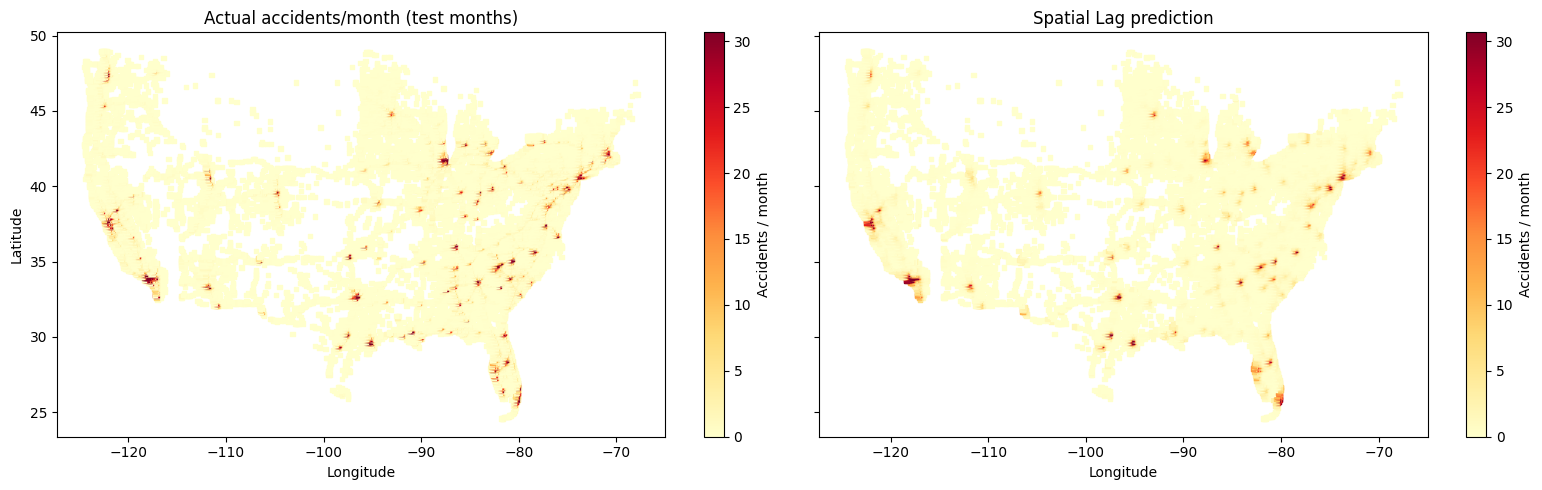

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharex=True, sharey=True)
vmax = np.percentile(y_test, 99)

for ax, vals, title in zip(axes, [y_test, np.clip(pred_lag, 0, None)],
                           ['Actual accidents/month (test months)', 'Spatial Lag prediction']):
    pts = ax.scatter(cells['lng'], cells['lat'], c=vals, cmap='YlOrRd',
                     s=10, marker='s', vmin=0, vmax=vmax)
    ax.set_title(title)
    ax.set_xlabel('Longitude')
    fig.colorbar(pts, ax=ax, label='Accidents / month')
axes[0].set_ylabel('Latitude')
plt.tight_layout()
plt.show()

## Part 6: Checking the Spatial Lag model against other models

Same cells, same time split, same road features as Part 5. If Spatial Lag still ranks well against these, the result is trustworthy.

Two kinds of rivals:
- **Normal models** that ignore neighbours: Ridge, KNN, Decision Tree, Random Forest, Gradient Boosting.
- **A fair fight:** Random Forest and Gradient Boosting that are *also given* the neighbours' average. This shows whether the Spatial Lag model wins because of the model itself, or just because it sees the neighbours.

### 6.1 Train the other models

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from scipy.stats import spearmanr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_log = y.ravel()                                  # log of train accidents/month
neighbour_avg = w.sparse @ y_log                   # neighbours' average (train months only)
X_nb = np.column_stack([X, neighbour_avg])         # road features + neighbours' average

# (model, which features it gets)
rivals = {
    'Ridge':                    (make_pipeline(StandardScaler(), Ridge()), X),
    'KNN':                      (make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=15)), X),
    'Decision Tree':            (DecisionTreeRegressor(max_depth=6, random_state=42), X),
    'Random Forest':            (RandomForestRegressor(n_estimators=300, max_depth=10, random_state=42, n_jobs=-1), X),
    'Gradient Boosting':        (HistGradientBoostingRegressor(random_state=42), X),
    'Random Forest + neighbours':     (RandomForestRegressor(n_estimators=300, max_depth=10, random_state=42, n_jobs=-1), X_nb),
    'Gradient Boosting + neighbours': (HistGradientBoostingRegressor(random_state=42), X_nb),
}

all_preds = {'Baseline (mean)': preds['Baseline (mean)'],
             'OLS': preds['OLS (no neighbours)'],
             'Spatial Lag': preds['Spatial Lag']}

for name, (model, feats) in rivals.items():
    model.fit(feats, y_log)
    all_preds[name] = np.expm1(model.predict(feats))

rows = []
for name, p in all_preds.items():
    p = np.clip(p, 0, None)
    rows.append({'Model': name,
                 'R2': r2_score(y_test, p),
                 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'Spearman': spearmanr(y_test, p)[0]})

compare = pd.DataFrame(rows).set_index('Model').sort_values('Spearman', ascending=False).round(3)
compare

/tmp/ipykernel_3177/945306764.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  'Spearman': spearmanr(y_test, p)[0]})


,R2,MAE,RMSE,Spearman
Model,,,,
Random Forest + neighbours,0.752,0.810,3.466,0.714
Gradient Boosting + neighbours,0.748,0.831,3.494,0.710
Random Forest,0.745,0.836,3.511,0.683
Gradient Boosting,0.694,0.911,3.846,0.674
KNN,0.298,1.287,5.830,0.663
Decision Tree,0.538,1.102,4.728,0.655
Spatial Lag,0.538,1.160,4.731,0.634
OLS,-0.002,1.698,6.965,0.464
Ridge,-0.002,1.698,6.965,0.464


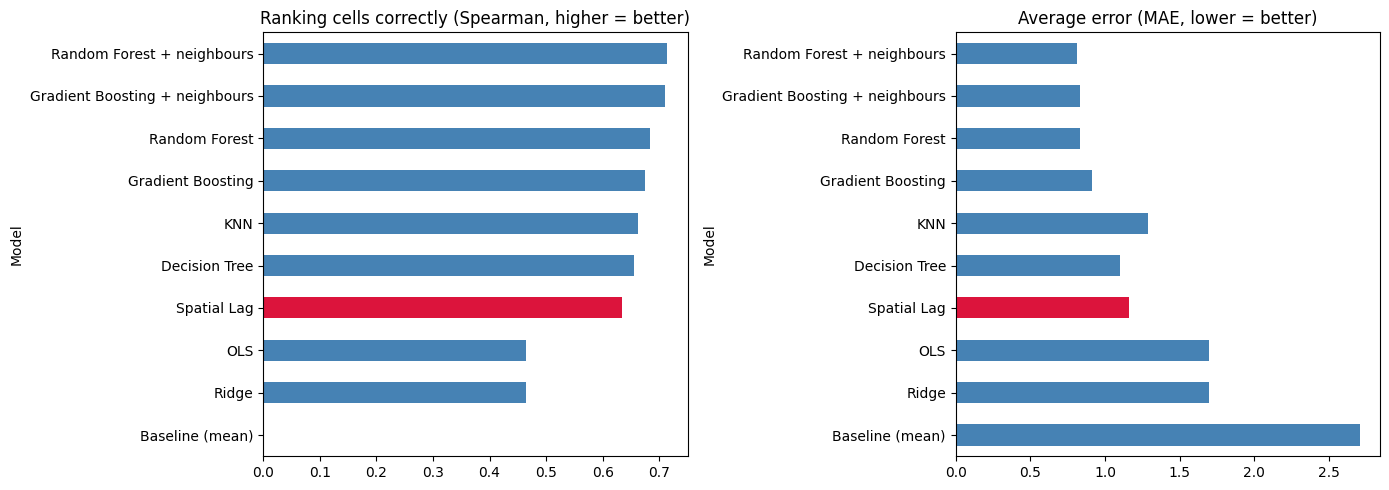

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['crimson' if m == 'Spatial Lag' else 'steelblue' for m in compare.index[::-1]]

compare['Spearman'][::-1].plot(kind='barh', ax=axes[0], color=colors)
axes[0].set_title('Ranking cells correctly (Spearman, higher = better)')

compare['MAE'][::-1].plot(kind='barh', ax=axes[1], color=colors)
axes[1].set_title('Average error (MAE, lower = better)')

plt.tight_layout()
plt.show()

### 6.2 Do the errors still cluster on the map?
**Moran's I** on each model's test errors. Close to 0 means the model has captured the neighbour pattern. Clearly above 0 means it is still missing something about location.

In [ ]:
from esda.moran import Moran

check = ['OLS', 'Random Forest', 'Random Forest + neighbours', 'Spatial Lag']
rows = []
for name in check:
    errors = y_test - np.clip(all_preds[name], 0, None)
    mi = Moran(errors, w, permutations=0)
    rows.append({'Model': name, "Moran's I of errors": round(mi.I, 3), 'p-value': round(mi.p_norm, 4)})

pd.DataFrame(rows).set_index('Model')

,Moran's I of errors,p-value
Model,,
OLS,0.514,0.0
Random Forest,0.272,0.0
Random Forest + neighbours,0.389,0.0
Spatial Lag,0.208,0.0


**How to read it:**
- If **Spatial Lag** beats the normal models and also beats the "+ neighbours" models, the spatial lag structure itself is adding value.
- If the "+ neighbours" models match or beat it, the gain comes from using neighbour information. That is still a valid finding, but say so in your write-up.
- If every model scores close to the mean baseline, the road features alone do not explain accident levels much.

## Part 7: Geographically Weighted Regression (GWR)

**Idea in plain words:** a normal regression gives one rule for the whole map (e.g. "junctions raise accidents by this much everywhere"). GWR gives **a different rule for each area**, built mostly from the cells around it. So it can show *where* junctions, signals or crossings matter more.

Same cells, same time split and same road features as Part 5, so the scores can be compared directly.

In [ ]:
%pip install mgwr

### 7.1 Choose how far "nearby" reaches
GWR needs to know how many neighbouring cells each local rule uses (the *bandwidth*). Searching on every cell would be very slow, so it is searched on a random sample of cells and scaled up.

**Rare features are left out of GWR.** A feature that is almost always 0 (like Railway) becomes all zeros inside a small local patch, and GWR cannot solve that (it fails with *"Matrix is singular"*). Only features that are non-zero in at least 10% of cells are used here.

In [ ]:
from mgwr.gwr import GWR
from mgwr.sel_bw import Sel_BW

# Keep only features that are non-zero in at least 10% of cells
nonzero_share = (cells[X_cols] > 0).mean()
gwr_cols = [c for c in X_cols if nonzero_share[c] >= 0.10]
print('Used in GWR :', gwr_cols)
print('Left out    :', [c for c in X_cols if c not in gwr_cols])

# Put every feature on the same scale so the local rules can be compared
Xg = cells[gwr_cols].values
g_std = Xg.std(axis=0)
g_std[g_std == 0] = 1
Xs = (Xg - Xg.mean(axis=0)) / g_std

# Search the bandwidth on a sample, then scale up to the full number of cells
rng = np.random.default_rng(42)
n_sub = min(3000, len(cells))
idx = rng.choice(len(cells), n_sub, replace=False)

bw_min = 100                      # never use fewer than this many neighbours
while True:
    try:
        bw_sub = Sel_BW(coords[idx], y[idx], Xs[idx], kernel='bisquare', fixed=False
                        ).search(criterion='AICc', bw_min=bw_min, bw_max=n_sub)
        break
    except np.linalg.LinAlgError:
        bw_min *= 2               # patch too small to solve: widen it and retry
        print(f'Singular matrix, retrying with at least {bw_min} neighbours')
        if bw_min >= n_sub // 2:
            raise

bw = max(int(bw_sub * len(cells) / n_sub), bw_min)
print(f'Each local rule uses about the nearest {bw} cells (out of {len(cells)})')

Used in GWR : ['Junction_share', 'Traffic_Signal_share', 'Crossing_share', 'Stop_share']
Left out    : ['Station_share', 'Amenity_share', 'Railway_share']
Each local rule uses about the nearest 650 cells (out of 19327)


### 7.2 Fit GWR (train months only)
This can take a few minutes with many cells.

In [ ]:
while True:
    try:
        gwr_model = GWR(coords, y, Xs, bw, kernel='bisquare', fixed=False)
        gwr_res = gwr_model.fit(lite=True)       # lite = skips heavy extra statistics
        break
    except np.linalg.LinAlgError:
        bw = int(bw * 1.5)                       # patch too small somewhere: widen it and retry
        print(f'Singular matrix, retrying with {bw} neighbours')

local = pd.DataFrame(gwr_res.params, columns=['Constant'] + gwr_cols)
local[['lat', 'lng']] = cells[['lat', 'lng']].values

# How much does each rule change across the map? (bigger spread = more local variation)
local[['Constant'] + gwr_cols].describe().loc[['mean', 'std', 'min', 'max']].round(4)

,Constant,Junction_share,Traffic_Signal_share,Crossing_share,Stop_share
mean,0.4573,0.2265,0.1875,0.1366,-0.0302
std,0.2221,0.1944,0.1261,0.1773,0.0561
min,0.0799,-0.0985,-0.0303,-0.2693,-0.2381
max,1.2329,1.2343,0.9630,1.1058,0.4956


### 7.3 Test on the later months
Each cell is predicted with **its own local rule** applied to its road features, then compared with the real accidents in the test months.

In [ ]:
Xs_c = np.hstack([np.ones((len(Xs), 1)), Xs])
pred_gwr = np.expm1((Xs_c * gwr_res.params).sum(axis=1))

all_preds['GWR'] = pred_gwr

rows = []
for name, p in all_preds.items():
    p = np.clip(p, 0, None)
    rows.append({'Model': name,
                 'R2': r2_score(y_test, p),
                 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'Spearman': spearmanr(y_test, p)[0]})

compare = pd.DataFrame(rows).set_index('Model').sort_values('Spearman', ascending=False).round(3)
compare

/tmp/ipykernel_3177/3072165215.py:13: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  'Spearman': spearmanr(y_test, p)[0]})


,R2,MAE,RMSE,Spearman
Model,,,,
Random Forest + neighbours,0.752,0.810,3.466,0.714
Gradient Boosting + neighbours,0.748,0.831,3.494,0.710
Random Forest,0.745,0.836,3.511,0.683
Gradient Boosting,0.694,0.911,3.846,0.674
KNN,0.298,1.287,5.830,0.663
Decision Tree,0.538,1.102,4.728,0.655
Spatial Lag,0.538,1.160,4.731,0.634
GWR,0.063,1.595,6.734,0.521
OLS,-0.002,1.698,6.965,0.464


In [ ]:
from esda.moran import Moran

rows = []
for name in ['OLS', 'Spatial Lag', 'GWR']:
    errors = y_test - np.clip(all_preds[name], 0, None)
    mi = Moran(errors, w, permutations=0)
    rows.append({'Model': name, "Moran's I of errors": round(mi.I, 3), 'p-value': round(mi.p_norm, 4)})

pd.DataFrame(rows).set_index('Model')

,Moran's I of errors,p-value
Model,,
OLS,0.514,0.0
Spatial Lag,0.208,0.0
GWR,0.435,0.0


### 7.4 Maps: where does each road feature matter most?
Each map colours every cell by how strongly that feature pushes accidents up (red) or down (blue) **in that area**.

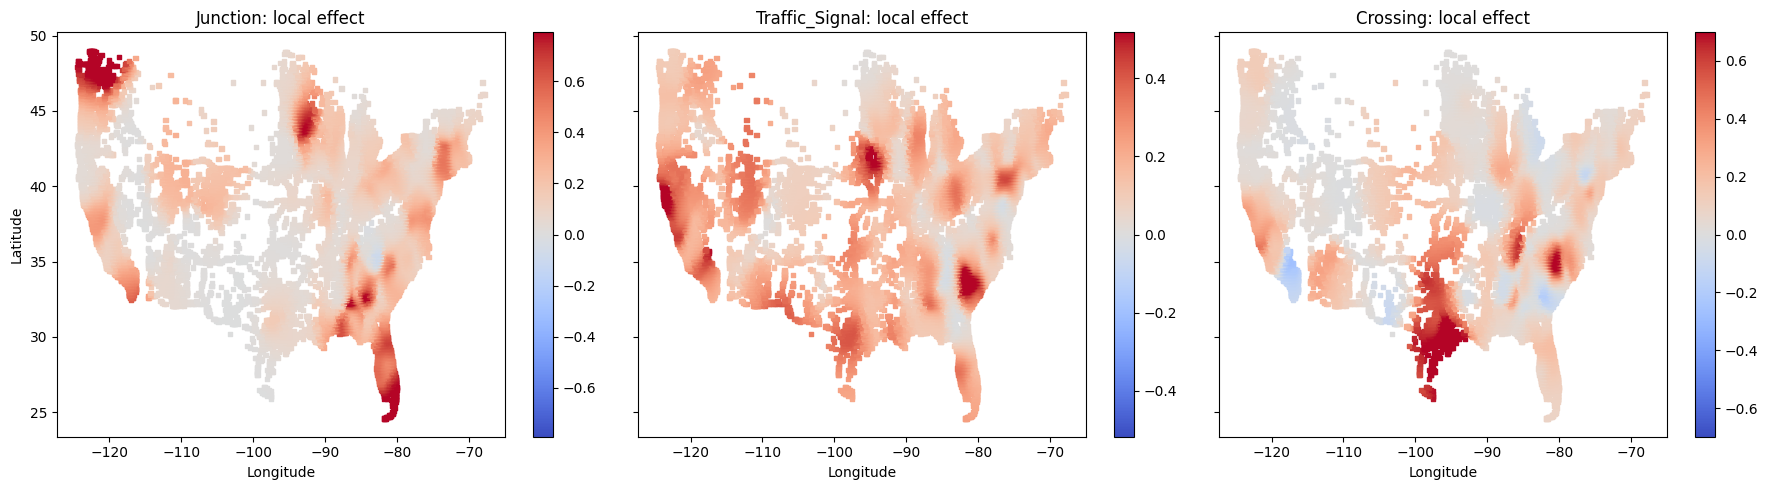

In [ ]:
import matplotlib.pyplot as plt

show = [f for f in ['Junction_share', 'Traffic_Signal_share', 'Crossing_share'] if f in gwr_cols] or gwr_cols[:3]
fig, axes = plt.subplots(1, len(show), figsize=(6 * len(show), 5), sharey=True, squeeze=False)
axes = axes[0]

for ax, feat in zip(axes, show):
    lim = np.percentile(np.abs(local[feat]), 98)
    pts = ax.scatter(local['lng'], local['lat'], c=local[feat], cmap='coolwarm',
                     vmin=-lim, vmax=lim, s=10, marker='s')
    ax.set_title(feat.replace('_share', '') + ': local effect')
    ax.set_xlabel('Longitude')
    fig.colorbar(pts, ax=ax)
axes[0].set_ylabel('Latitude')
plt.tight_layout()
plt.show()

**How to read it:**
- If the maps are mostly one colour, the same rule works everywhere and GWR adds little over the normal regression.
- If colours change from region to region, road features matter differently in different places. That is what GWR is for.
- Compare GWR with Spatial Lag in the table. They answer different questions: Spatial Lag asks *do neighbours influence each other?*, GWR asks *do the rules change from place to place?*

## Part 8: Real road features from OpenStreetMap (whole US)

Until now the road features were **made from the accidents** (e.g. "30% of accidents here were near a junction"). That is circular: the features are built from the same accidents we are trying to predict.

Here the features come from **OpenStreetMap (OSM)**, a free map of the real world. For each grid cell we count what is physically there: traffic signals, crossings, stop signs, motorway exits, railway crossings, stations and amenities. Nothing in these counts depends on where accidents happened.

**Flow:**
1. Run 8.1 to 8.3 (long download, runs once).
2. **Re-run from 5.4 down to the end of Part 7.** Those cells now use the OSM features.
3. Run 8.4 to compare the two versions.

**Good to know:**
- The map file is about 10 GB, so the download and filtering take a while (roughly 30 to 60 minutes). Everything is read as a stream, so it does not fill the memory.
- The map is today's, the accidents are from 2016 to 2018. A few roads or signals may be newer than the accidents.
- Only point features are counted (signals, crossings and so on). Road length and true intersections need a heavier step.

### 8.1 Download the US map and keep only the points we need

In [ ]:
# Save the accident-feature results so we can compare later
compare_accident_features = compare.copy()

!apt-get -qq install -y osmium-tool
%pip install osmium

# ~10 GB download
!wget -q -c -O us.osm.pbf https://download.geofabrik.de/north-america/us-latest.osm.pbf

# Keep only the points we count (this is the slow step)
!osmium tags-filter us.osm.pbf n/highway=traffic_signals,crossing,stop,motorway_junction n/railway=level_crossing,station n/public_transport=station n/amenity -o us_points.osm.pbf --overwrite

!ls -lh us.osm.pbf us_points.osm.pbf

Selecting previously unselected package libboost-program-options1.83.0:amd64.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../libboost-program-options1.83.0_1.83.0-2.1ubuntu3.2_amd64.deb ...
Unpacking libboost-program-options1.83.0:amd64 (1.83.0-2.1ubuntu3.2) ...
Selecting previously unselected package osmium-tool.
Preparing to unpack .../osmium-tool_1.16.0-1build1_amd64.deb ...
Unpacking osmium-tool (1.16.0-1build1) ...
Setting up libboost-program-options1.83.0:amd64 (1.83.0-2.1ubuntu3.2) ...
Setting up osmium-tool (1.16.0-1build1) ...
Processing triggers for libc-bin (2.39-0ubuntu8.9) ...
/sbin/ldconfig.real: /usr/local/lib/libtcm.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtcm_debug.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_0.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.1

### 8.2 Count the points in each grid cell
Uses the same grid as your accident cells (`Grid_round_off`), so the two line up exactly.

In [ ]:
import osmium
from collections import defaultdict

OSM_NAMES = ['Signals', 'Crossings', 'Stops', 'Motorway_exits', 'Rail_crossings', 'Stations', 'Amenities']
FACTOR = 10 ** Grid_round_off          # same grid as the accident cells


class CellCounter(osmium.SimpleHandler):
    def __init__(self):
        super().__init__()
        self.counts = defaultdict(lambda: [0] * len(OSM_NAMES))

    def node(self, n):
        t = n.tags
        hw, rw, pt, am = t.get('highway'), t.get('railway'), t.get('public_transport'), t.get('amenity')

        hit = []
        if hw == 'traffic_signals':    hit.append(0)
        if hw == 'crossing':           hit.append(1)
        if hw == 'stop':               hit.append(2)
        if hw == 'motorway_junction':  hit.append(3)
        if rw == 'level_crossing':     hit.append(4)
        if rw == 'station' or pt == 'station': hit.append(5)
        if am is not None:             hit.append(6)
        if not hit or not n.location.valid():
            return

        key = (round(n.location.lat * FACTOR), round(n.location.lon * FACTOR))
        row = self.counts[key]
        for i in hit:
            row[i] += 1


counter = CellCounter()
counter.apply_file('us_points.osm.pbf')

osm = pd.DataFrame([(k[0], k[1], *v) for k, v in counter.counts.items()],
                   columns=['ilat', 'ilng'] + OSM_NAMES)
osm['cell'] = (osm['ilat'] / FACTOR).astype(str) + '_' + (osm['ilng'] / FACTOR).astype(str)
osm_by_cell = osm.groupby('cell')[OSM_NAMES].sum().add_prefix('osm_')

print('Cells with OSM points:', len(osm_by_cell))
print('Total points counted :', int(osm_by_cell.sum().sum()))
osm_by_cell.sum()

Cells with OSM points: 54548
Total points counted : 8600750


,0
osm_Signals,549506
osm_Crossings,4810082
osm_Stops,1071690
osm_Motorway_exits,77436
osm_Rail_crossings,273012
osm_Stations,7814
osm_Amenities,1811210


### 8.3 Swap the accident-based features for the OSM ones
Counts are very skewed (a big city has thousands, a village has a few), so they are put on a log scale.

In [ ]:
osm_cols = list(osm_by_cell.columns)

# Remove any earlier OSM columns, then attach the new ones (row order stays the same)
cells = cells.drop(columns=[c for c in cells.columns if c.startswith('osm_')], errors='ignore')
cells = cells.merge(osm_by_cell, on='cell', how='left')
cells[osm_cols] = np.log1p(cells[osm_cols].fillna(0))

matched = (cells[osm_cols].sum(axis=1) > 0).mean()
print(f'Accident cells that found OSM points: {matched:.1%}')
if matched < 0.5:
    print('Warning: very few cells matched. Check that Grid_round_off is the same as in the accident grid cell.')

FEATURE_COLS = osm_cols
print('Features now used:', FEATURE_COLS)
print('\nNow re-run from 5.4 down to the end of Part 7.')

Accident cells that found OSM points: 95.4%
Features now used: ['osm_Signals', 'osm_Crossings', 'osm_Stops', 'osm_Motorway_exits', 'osm_Rail_crossings', 'osm_Stations', 'osm_Amenities']

Now re-run from 5.4 down to the end of Part 7.


# Rerun 5.4 to end of 7

### 5.4 Fit: normal regression vs spatial lag
First a normal (OLS) regression, plus **Moran's I** on its errors. If Moran's I is clearly above 0 with a tiny p-value, the errors cluster on the map, which means neighbours matter and a spatial model is justified.

In [ ]:
import spreg

X_cols = FEATURE_COLS
X = cells[X_cols].values
y = np.log1p(cells[['train_rate']].values)      # log scale, as in Part 4

# Normal regression (no neighbours)
ols = spreg.OLS(y, X, w=w, spat_diag=True, moran=True, name_x=X_cols, name_y='log_rate')
print(f"OLS errors, Moran's I = {ols.moran_res[0]:.3f}  (p = {ols.moran_res[2]:.4f})")

# Spatial lag regression (neighbours included)
lag = spreg.GM_Lag(y, X, w=w, name_x=X_cols, name_y='log_rate')
rho = lag.betas[-1, 0]
print(f'\nSpatial lag strength (rho) = {rho:.3f}   (0 = neighbours do not matter, closer to 1 = matter a lot)')
if rho >= 1:
    print('Warning: rho >= 1 is unstable. Try a smaller k in Part 5.3 or a coarser grid.')

coef = pd.DataFrame({'Feature': ['Constant'] + X_cols,
                     'OLS': ols.betas[:, 0],
                     'Spatial lag': lag.betas[:-1, 0]})
coef

OLS errors, Moran's I = 0.526  (p = 0.0000)
GM_Lag

Spatial lag strength (rho) = 0.486   (0 = neighbours do not matter, closer to 1 = matter a lot)


,Feature,OLS,Spatial lag
0,Constant,-0.025979,-0.094174
1,osm_Signals,0.167654,0.101491
2,osm_Crossings,-0.001341,-0.007306
3,osm_Stops,0.052088,0.026100
4,osm_Motorway_exits,0.192352,0.174062
5,osm_Rail_crossings,-0.031874,-0.008159
6,osm_Stations,0.358779,0.207794
7,osm_Amenities,0.000348,-0.002302


### 5.5 Test on the later months
The model predicts each cell from its **road features** plus **what its 8 neighbours looked like in the training months**: predicted = ρ · (neighbours' average) + Xβ.

Scores use the original accidents-per-month scale. **Spearman** checks whether the model ranks cells in the right order, which is what matters for finding accident-prone areas.

In [ ]:
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Xc = np.hstack([np.ones((len(X), 1)), X])          # add the constant column
y_test = cells['test_rate'].values

# Predictions on the later months
pred_ols = np.expm1(Xc @ ols.betas[:, 0])

# Spatial lag: neighbours' average (from the train months) x rho  +  road features
neighbour_avg = w.sparse @ y.ravel()
pred_lag = np.expm1(rho * neighbour_avg + Xc @ lag.betas[:-1, 0])

rf = RandomForestRegressor(n_estimators=300, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X, y.ravel())
pred_rf = np.expm1(rf.predict(X))

pred_mean = np.full(len(y_test), cells['train_rate'].mean())

preds = {'Baseline (mean)': pred_mean, 'OLS (no neighbours)': pred_ols,
         'Random Forest': pred_rf, 'Spatial Lag': pred_lag}

rows = []
for name, p in preds.items():
    p = np.clip(p, 0, None)
    rows.append({'Model': name,
                 'R2': r2_score(y_test, p),
                 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'Spearman': spearmanr(y_test, p)[0]})

results = pd.DataFrame(rows).set_index('Model').round(3)
results

/tmp/ipykernel_3177/1473570732.py:31: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  'Spearman': spearmanr(y_test, p)[0]})


,R2,MAE,RMSE,Spearman
Model,,,,
Baseline (mean),-0.003,2.707,6.968,NaN
OLS (no neighbours),0.321,1.307,5.734,0.591
Random Forest,0.705,0.926,3.778,0.629
Spatial Lag,0.534,1.058,4.751,0.680


### 5.6 Map: predicted vs actual (test months)

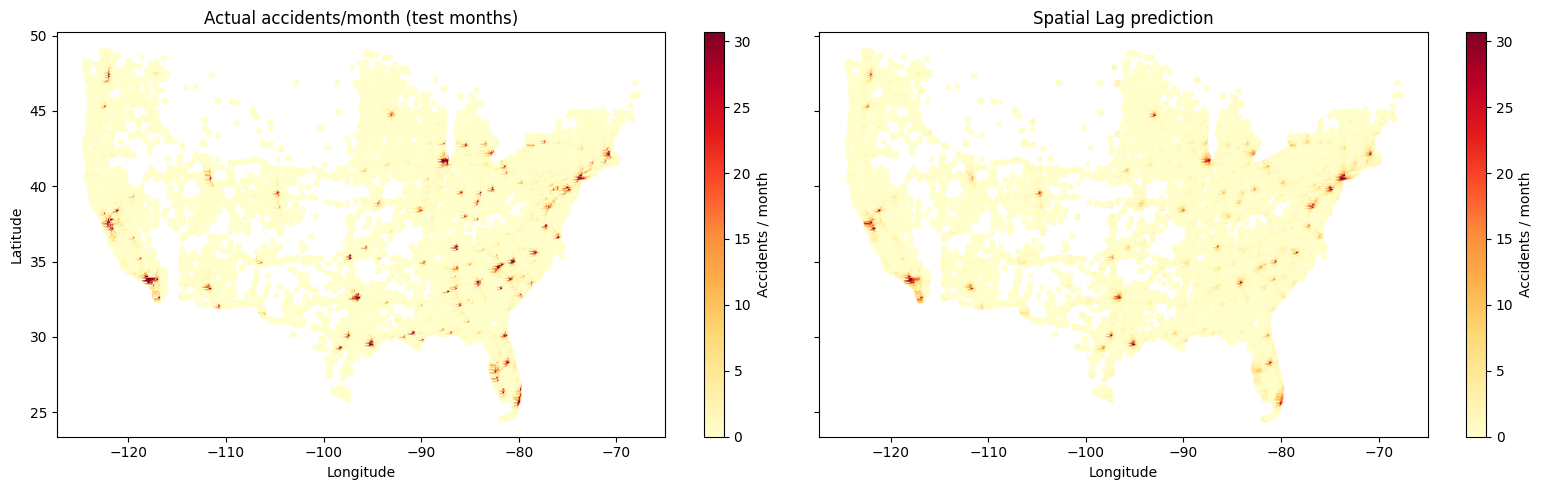

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharex=True, sharey=True)
vmax = np.percentile(y_test, 99)

for ax, vals, title in zip(axes, [y_test, np.clip(pred_lag, 0, None)],
                           ['Actual accidents/month (test months)', 'Spatial Lag prediction']):
    pts = ax.scatter(cells['lng'], cells['lat'], c=vals, cmap='YlOrRd',
                     s=10, marker='s', vmin=0, vmax=vmax)
    ax.set_title(title)
    ax.set_xlabel('Longitude')
    fig.colorbar(pts, ax=ax, label='Accidents / month')
axes[0].set_ylabel('Latitude')
plt.tight_layout()
plt.show()

## Part 6: Checking the Spatial Lag model against other models

Same cells, same time split, same road features as Part 5. If Spatial Lag still ranks well against these, the result is trustworthy.

Two kinds of rivals:
- **Normal models** that ignore neighbours: Ridge, KNN, Decision Tree, Random Forest, Gradient Boosting.
- **A fair fight:** Random Forest and Gradient Boosting that are *also given* the neighbours' average. This shows whether the Spatial Lag model wins because of the model itself, or just because it sees the neighbours.

### 6.1 Train the other models

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from scipy.stats import spearmanr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_log = y.ravel()                                  # log of train accidents/month
neighbour_avg = w.sparse @ y_log                   # neighbours' average (train months only)
X_nb = np.column_stack([X, neighbour_avg])         # road features + neighbours' average

# (model, which features it gets)
rivals = {
    'Ridge':                    (make_pipeline(StandardScaler(), Ridge()), X),
    'KNN':                      (make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=15)), X),
    'Decision Tree':            (DecisionTreeRegressor(max_depth=6, random_state=42), X),
    'Random Forest':            (RandomForestRegressor(n_estimators=300, max_depth=10, random_state=42, n_jobs=-1), X),
    'Gradient Boosting':        (HistGradientBoostingRegressor(random_state=42), X),
    'Random Forest + neighbours':     (RandomForestRegressor(n_estimators=300, max_depth=10, random_state=42, n_jobs=-1), X_nb),
    'Gradient Boosting + neighbours': (HistGradientBoostingRegressor(random_state=42), X_nb),
}

all_preds = {'Baseline (mean)': preds['Baseline (mean)'],
             'OLS': preds['OLS (no neighbours)'],
             'Spatial Lag': preds['Spatial Lag']}

for name, (model, feats) in rivals.items():
    model.fit(feats, y_log)
    all_preds[name] = np.expm1(model.predict(feats))

rows = []
for name, p in all_preds.items():
    p = np.clip(p, 0, None)
    rows.append({'Model': name,
                 'R2': r2_score(y_test, p),
                 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'Spearman': spearmanr(y_test, p)[0]})

compare = pd.DataFrame(rows).set_index('Model').sort_values('Spearman', ascending=False).round(3)
compare

/tmp/ipykernel_3177/945306764.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  'Spearman': spearmanr(y_test, p)[0]})


,R2,MAE,RMSE,Spearman
Model,,,,
Random Forest + neighbours,0.736,0.818,3.573,0.737
Gradient Boosting + neighbours,0.732,0.873,3.601,0.723
Spatial Lag,0.534,1.058,4.751,0.680
Random Forest,0.705,0.926,3.778,0.629
KNN,0.534,1.133,4.750,0.607
Gradient Boosting,0.601,1.037,4.393,0.605
Ridge,0.321,1.307,5.734,0.591
OLS,0.321,1.307,5.734,0.591
Decision Tree,0.530,1.136,4.773,0.587


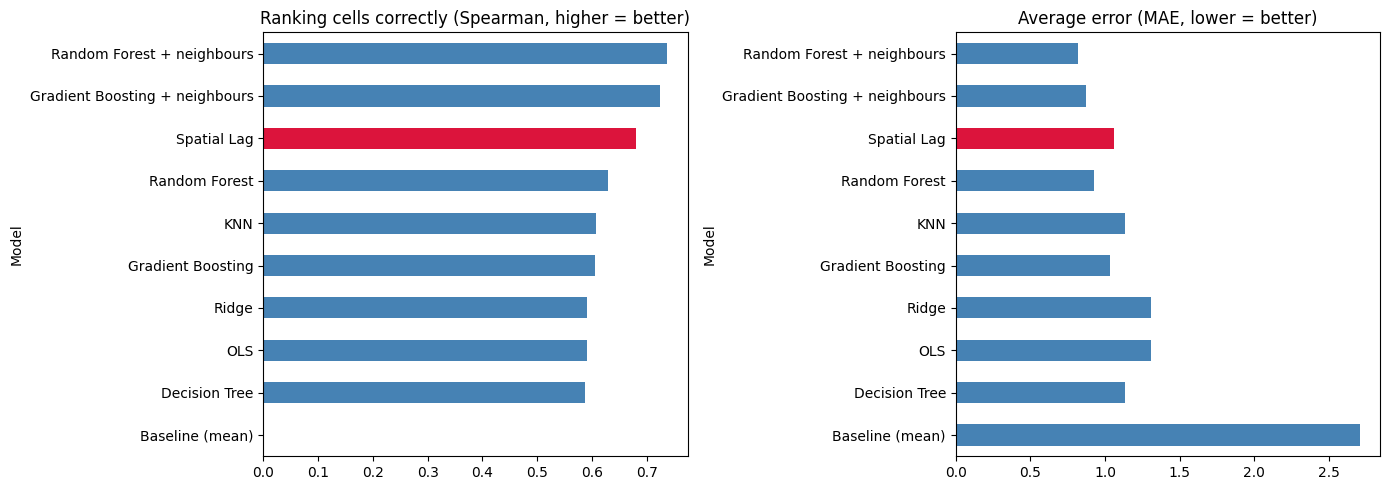

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['crimson' if m == 'Spatial Lag' else 'steelblue' for m in compare.index[::-1]]

compare['Spearman'][::-1].plot(kind='barh', ax=axes[0], color=colors)
axes[0].set_title('Ranking cells correctly (Spearman, higher = better)')

compare['MAE'][::-1].plot(kind='barh', ax=axes[1], color=colors)
axes[1].set_title('Average error (MAE, lower = better)')

plt.tight_layout()
plt.show()

### 6.2 Do the errors still cluster on the map?
**Moran's I** on each model's test errors. Close to 0 means the model has captured the neighbour pattern. Clearly above 0 means it is still missing something about location.

In [ ]:
from esda.moran import Moran

check = ['OLS', 'Random Forest', 'Random Forest + neighbours', 'Spatial Lag']
rows = []
for name in check:
    errors = y_test - np.clip(all_preds[name], 0, None)
    mi = Moran(errors, w, permutations=0)
    rows.append({'Model': name, "Moran's I of errors": round(mi.I, 3), 'p-value': round(mi.p_norm, 4)})

pd.DataFrame(rows).set_index('Model')

,Moran's I of errors,p-value
Model,,
OLS,0.491,0.0
Random Forest,0.455,0.0
Random Forest + neighbours,0.473,0.0
Spatial Lag,0.384,0.0


**How to read it:**
- If **Spatial Lag** beats the normal models and also beats the "+ neighbours" models, the spatial lag structure itself is adding value.
- If the "+ neighbours" models match or beat it, the gain comes from using neighbour information. That is still a valid finding, but say so in your write-up.
- If every model scores close to the mean baseline, the road features alone do not explain accident levels much.

## Part 7: Geographically Weighted Regression (GWR)

**Idea in plain words:** a normal regression gives one rule for the whole map (e.g. "junctions raise accidents by this much everywhere"). GWR gives **a different rule for each area**, built mostly from the cells around it. So it can show *where* junctions, signals or crossings matter more.

Same cells, same time split and same road features as Part 5, so the scores can be compared directly.

In [ ]:
%pip install mgwr

### 7.1 Choose how far "nearby" reaches
GWR needs to know how many neighbouring cells each local rule uses (the *bandwidth*). Searching on every cell would be very slow, so it is searched on a random sample of cells and scaled up.

**Rare features are left out of GWR.** A feature that is almost always 0 (like Railway) becomes all zeros inside a small local patch, and GWR cannot solve that (it fails with *"Matrix is singular"*). Only features that are non-zero in at least 10% of cells are used here.

In [ ]:
from mgwr.gwr import GWR
from mgwr.sel_bw import Sel_BW

# Keep only features that are non-zero in at least 10% of cells
nonzero_share = (cells[X_cols] > 0).mean()
gwr_cols = [c for c in X_cols if nonzero_share[c] >= 0.10]
print('Used in GWR :', gwr_cols)
print('Left out    :', [c for c in X_cols if c not in gwr_cols])

# Put every feature on the same scale so the local rules can be compared
Xg = cells[gwr_cols].values
g_std = Xg.std(axis=0)
g_std[g_std == 0] = 1
Xs = (Xg - Xg.mean(axis=0)) / g_std

# Search the bandwidth on a sample, then scale up to the full number of cells
rng = np.random.default_rng(42)
n_sub = min(3000, len(cells))
idx = rng.choice(len(cells), n_sub, replace=False)

bw_min = 100                      # never use fewer than this many neighbours
while True:
    try:
        bw_sub = Sel_BW(coords[idx], y[idx], Xs[idx], kernel='bisquare', fixed=False
                        ).search(criterion='AICc', bw_min=bw_min, bw_max=n_sub)
        break
    except np.linalg.LinAlgError:
        bw_min *= 2               # patch too small to solve: widen it and retry
        print(f'Singular matrix, retrying with at least {bw_min} neighbours')
        if bw_min >= n_sub // 2:
            raise

bw = max(int(bw_sub * len(cells) / n_sub), bw_min)
print(f'Each local rule uses about the nearest {bw} cells (out of {len(cells)})')

Used in GWR : ['osm_Signals', 'osm_Crossings', 'osm_Stops', 'osm_Motorway_exits', 'osm_Rail_crossings', 'osm_Amenities']
Left out    : ['osm_Stations']
Each local rule uses about the nearest 676 cells (out of 19327)


### 7.2 Fit GWR (train months only)
This can take a few minutes with many cells.

In [ ]:
while True:
    try:
        gwr_model = GWR(coords, y, Xs, bw, kernel='bisquare', fixed=False)
        gwr_res = gwr_model.fit(lite=True)       # lite = skips heavy extra statistics
        break
    except np.linalg.LinAlgError:
        bw = int(bw * 1.5)                       # patch too small somewhere: widen it and retry
        print(f'Singular matrix, retrying with {bw} neighbours')

local = pd.DataFrame(gwr_res.params, columns=['Constant'] + gwr_cols)
local[['lat', 'lng']] = cells[['lat', 'lng']].values

# How much does each rule change across the map? (bigger spread = more local variation)
local[['Constant'] + gwr_cols].describe().loc[['mean', 'std', 'min', 'max']].round(4)

,Constant,osm_Signals,osm_Crossings,osm_Stops,osm_Motorway_exits,osm_Rail_crossings,osm_Amenities
mean,0.4469,0.2470,0.0340,0.0446,0.2571,-0.0010,0.0636
std,0.2187,0.1471,0.1642,0.0807,0.1255,0.0530,0.1023
min,0.1006,-0.1820,-0.3169,-0.2485,-0.0290,-0.1531,-0.3944
max,1.2488,0.7136,0.6009,0.4112,0.6237,0.1887,0.3912


### 7.3 Test on the later months
Each cell is predicted with **its own local rule** applied to its road features, then compared with the real accidents in the test months.

In [ ]:
Xs_c = np.hstack([np.ones((len(Xs), 1)), Xs])
pred_gwr = np.expm1((Xs_c * gwr_res.params).sum(axis=1))

all_preds['GWR'] = pred_gwr

rows = []
for name, p in all_preds.items():
    p = np.clip(p, 0, None)
    rows.append({'Model': name,
                 'R2': r2_score(y_test, p),
                 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'Spearman': spearmanr(y_test, p)[0]})

compare = pd.DataFrame(rows).set_index('Model').sort_values('Spearman', ascending=False).round(3)
compare

/tmp/ipykernel_3177/3072165215.py:13: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  'Spearman': spearmanr(y_test, p)[0]})


,R2,MAE,RMSE,Spearman
Model,,,,
Random Forest + neighbours,0.736,0.818,3.573,0.737
Gradient Boosting + neighbours,0.732,0.873,3.601,0.723
Spatial Lag,0.534,1.058,4.751,0.680
GWR,0.446,1.130,5.178,0.677
Random Forest,0.705,0.926,3.778,0.629
KNN,0.534,1.133,4.750,0.607
Gradient Boosting,0.601,1.037,4.393,0.605
Ridge,0.321,1.307,5.734,0.591
OLS,0.321,1.307,5.734,0.591


In [ ]:
from esda.moran import Moran

rows = []
for name in ['OLS', 'Spatial Lag', 'GWR']:
    errors = y_test - np.clip(all_preds[name], 0, None)
    mi = Moran(errors, w, permutations=0)
    rows.append({'Model': name, "Moran's I of errors": round(mi.I, 3), 'p-value': round(mi.p_norm, 4)})

pd.DataFrame(rows).set_index('Model')

,Moran's I of errors,p-value
Model,,
OLS,0.491,0.0
Spatial Lag,0.384,0.0
GWR,0.446,0.0


### 7.4 Maps: where does each road feature matter most?
Each map colours every cell by how strongly that feature pushes accidents up (red) or down (blue) **in that area**.

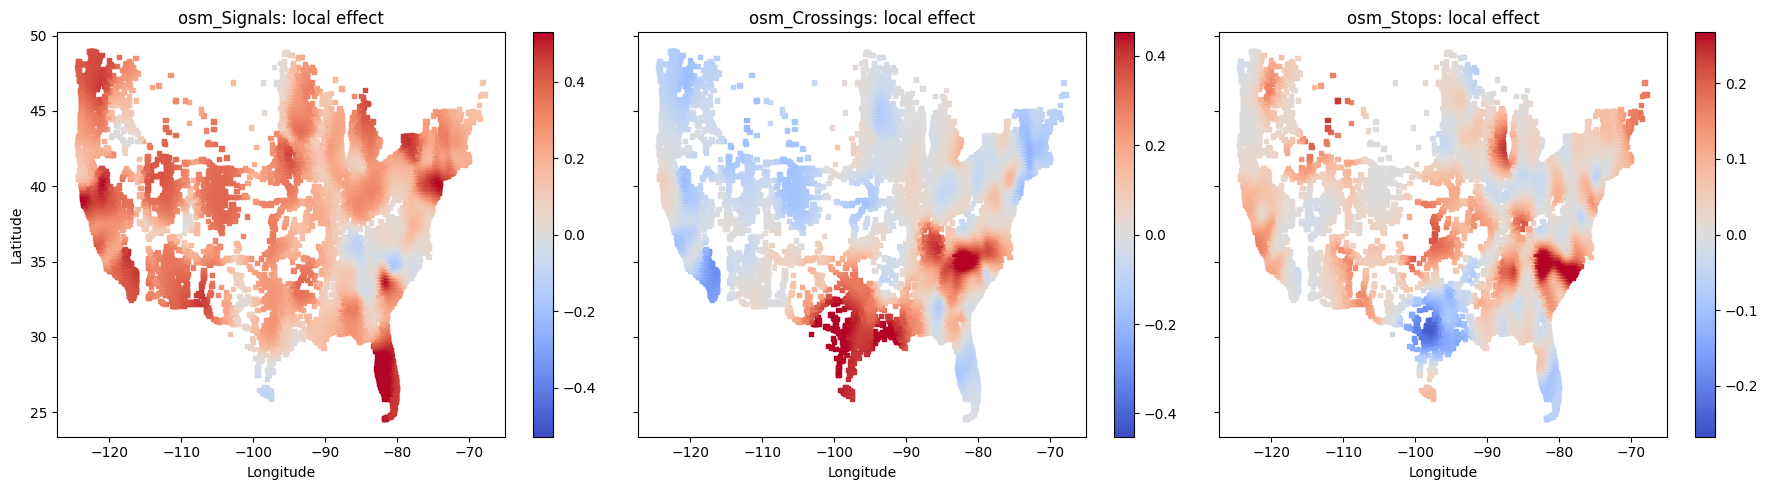

In [ ]:
import matplotlib.pyplot as plt

show = [f for f in ['Junction_share', 'Traffic_Signal_share', 'Crossing_share'] if f in gwr_cols] or gwr_cols[:3]
fig, axes = plt.subplots(1, len(show), figsize=(6 * len(show), 5), sharey=True, squeeze=False)
axes = axes[0]

for ax, feat in zip(axes, show):
    lim = np.percentile(np.abs(local[feat]), 98)
    pts = ax.scatter(local['lng'], local['lat'], c=local[feat], cmap='coolwarm',
                     vmin=-lim, vmax=lim, s=10, marker='s')
    ax.set_title(feat.replace('_share', '') + ': local effect')
    ax.set_xlabel('Longitude')
    fig.colorbar(pts, ax=ax)
axes[0].set_ylabel('Latitude')
plt.tight_layout()
plt.show()

**How to read it:**
- If the maps are mostly one colour, the same rule works everywhere and GWR adds little over the normal regression.
- If colours change from region to region, road features matter differently in different places. That is what GWR is for.
- Compare GWR with Spatial Lag in the table. They answer different questions: Spatial Lag asks *do neighbours influence each other?*, GWR asks *do the rules change from place to place?*

# 8.4 Accident-based features vs real road features
Run this after re-running 5.4 to Part 7.

In [ ]:
both = compare_accident_features[['R2', 'Spearman']].join(
    compare[['R2', 'Spearman']], lsuffix=' (accident-based)', rsuffix=' (OSM)')

both = both[['R2 (accident-based)', 'R2 (OSM)', 'Spearman (accident-based)', 'Spearman (OSM)']]
both.sort_values('Spearman (OSM)', ascending=False)

,R2 (accident-based),R2 (OSM),Spearman (accident-based),Spearman (OSM)
Model,,,,
Random Forest + neighbours,0.752,0.736,0.714,0.737
Gradient Boosting + neighbours,0.748,0.732,0.710,0.723
Spatial Lag,0.538,0.534,0.634,0.680
GWR,0.063,0.446,0.521,0.677
Random Forest,0.745,0.705,0.683,0.629
KNN,0.298,0.534,0.663,0.607
Gradient Boosting,0.694,0.601,0.674,0.605
OLS,-0.002,0.321,0.464,0.591
Ridge,-0.002,0.321,0.464,0.591


**How to read it:**
- If scores **drop** with OSM features, the earlier scores were partly inflated by the circular features. The OSM numbers are the honest ones.
- If scores **hold up or rise**, road features really do explain accident levels, and the model is on solid ground.
- Either way, report the OSM version: it is the one that does not depend on the accidents it is predicting.

In [ ]:
LEVELS = [0.05, 0.10, 0.20]      # hotspot = top 5%, 10%, 20% of cells

def top_cells(values, frac):
    k = int(len(values) * frac)
    return set(np.argsort(-values, kind='stable')[:k])

rows = []
for name, p in all_preds.items():
    if name == 'Baseline (mean)':
        continue                                   # constant guess, nothing to rank
    p = np.clip(p, 0, None)
    row = {'Model': name}
    for frac in LEVELS:
        real = top_cells(y_test, frac)             # the real hotspots (test months)
        picked = top_cells(p, frac)                # the model's hotspots
        row[f'Hit rate top {int(frac * 100)}%'] = len(real & picked) / len(real)
    picked10 = list(top_cells(p, 0.10))
    row['Accidents inside its top 10%'] = y_test[picked10].sum() / y_test.sum()
    rows.append(row)

hotspots = (pd.DataFrame(rows).set_index('Model')
              .sort_values('Hit rate top 10%', ascending=False).round(3))

best_possible = y_test[list(top_cells(y_test, 0.10))].sum() / y_test.sum()
print('Random guessing would hit 5% / 10% / 20% of the real hotspots.')
print(f'Best possible share of accidents inside a top-10% pick: {best_possible:.3f}')
hotspots

Random guessing would hit 5% / 10% / 20% of the real hotspots.
Best possible share of accidents inside a top-10% pick: 0.843


,Hit rate top 5%,Hit rate top 10%,Hit rate top 20%,Accidents inside its top 10%
Model,,,,
Random Forest + neighbours,0.818,0.817,0.781,0.815
Gradient Boosting + neighbours,0.801,0.786,0.757,0.805
Spatial Lag,0.745,0.754,0.718,0.790
Random Forest,0.764,0.746,0.716,0.789
GWR,0.685,0.731,0.725,0.777
Gradient Boosting,0.723,0.712,0.676,0.767
KNN,0.665,0.682,0.671,0.746
Decision Tree,0.670,0.682,0.662,0.755
OLS,0.628,0.659,0.655,0.723


In [ ]:
MODEL = 'Random Forest + neighbours'      # any name from all_preds, e.g. 'Spatial Lag'

pred = np.clip(all_preds[MODEL], 0, None)          # predicted accidents per month, per cell

risk = cells[['cell', 'lat', 'lng']].copy()
risk['accidents_per_month'] = pred

# 1) Risk percentile: "this area is riskier than X% of all areas"
risk['risk_percent'] = (risk['accidents_per_month'].rank(pct=True) * 100).round(1)

# 2) Risk level (hotspot = top 10%, the group we tested above)
risk['risk_level'] = pd.cut(risk['risk_percent'], [0, 50, 80, 90, 100],
                            labels=['Low', 'Moderate', 'High', 'Hotspot'], include_lowest=True)

# 3) Chance of at least one accident in the area (Poisson: 1 - e^-rate)
for label, days in [('day', 1), ('week', 7), ('month', 30.4)]:
    rate = risk['accidents_per_month'] * days / 30.4
    risk[f'chance_1plus_per_{label}_%'] = ((1 - np.exp(-rate)) * 100).round(1)

# Sanity check: is the predicted total close to the real total in the test months?
print(f"Predicted vs actual accidents/month (all cells): {pred.sum():,.0f} vs {y_test.sum():,.0f} "
      f"(ratio {pred.sum() / y_test.sum():.2f})")

risk.to_csv('risk_table.csv', index=False)         # file for the app to read


def risk_at(lat, lng):
    key = f"{np.round(lat, Grid_round_off)}_{np.round(lng, Grid_round_off)}"
    row = risk[risk['cell'] == key]
    return row.iloc[0].to_dict() if len(row) else f'No data for area {key}'


print(risk['risk_level'].value_counts().to_string(), '\n')
risk.sort_values('risk_percent', ascending=False).head(10)

Predicted vs actual accidents/month (all cells): 33,010 vs 31,315 (ratio 1.05)
risk_level
Low         9673
Moderate    5798
High        1932
Hotspot     1924 



,cell,lat,lng,accidents_per_month,risk_percent,risk_level,chance_1plus_per_day_%,chance_1plus_per_week_%,chance_1plus_per_month_%
3200,32.8_-96.8,32.8,-96.8,218.732078,100.0,Hotspot,99.9,100.0,100.0
952,29.8_-95.4,29.8,-95.4,180.516687,100.0,Hotspot,99.7,100.0,100.0
1330,30.3_-97.7,30.3,-97.7,214.161177,100.0,Hotspot,99.9,100.0,100.0
6176,35.2_-80.8,35.2,-80.8,186.967104,100.0,Hotspot,99.8,100.0,100.0
893,29.7_-95.4,29.7,-95.4,175.608139,100.0,Hotspot,99.7,100.0,100.0
894,29.7_-95.5,29.7,-95.5,151.170150,100.0,Hotspot,99.3,100.0,100.0
4509,34.0_-118.2,34.0,-118.2,175.152781,100.0,Hotspot,99.7,100.0,100.0
4510,34.0_-118.3,34.0,-118.3,156.171687,100.0,Hotspot,99.4,100.0,100.0
4652,34.1_-118.2,34.1,-118.2,146.168897,100.0,Hotspot,99.2,100.0,100.0
1438,30.4_-97.7,30.4,-97.7,150.584165,100.0,Hotspot,99.3,100.0,100.0


In [ ]:
MODEL = 'Random Forest + neighbours'      # any name from all_preds, e.g. 'Spatial Lag'
# MODEL = 'Spatial Lag'

pred = np.clip(all_preds[MODEL], 0, None)          # predicted accidents per month, per cell

risk = cells[['cell', 'lat', 'lng']].copy()
risk['accidents_per_month'] = pred.round(2)
risk['accidents_per_day'] = (pred / 30.4).round(2)

# 1) Risk percent: "riskier than X% of all areas" (2 decimals so the top cells don't all read 100)
risk['risk_percent'] = (risk['accidents_per_month'].rank(pct=True) * 100).round(2)

# 2) Risk score 0-100 on a log scale (100 = the busiest area): separates big cities from each other
risk['risk_score'] = (np.log1p(pred) / np.log1p(pred.max()) * 100).round(1)

# 3) Risk level (Hotspot = top 10%, the group we tested; Extreme = top 1%)
risk['risk_level'] = pd.cut(risk['risk_percent'], [0, 50, 80, 90, 99, 100],
                            labels=['Low', 'Moderate', 'High', 'Hotspot', 'Extreme hotspot'],
                            include_lowest=True)

# 4) Chance of at least one accident in the area (Poisson: 1 - e^-rate), per hour and per day
risk['chance_1plus_per_hour_%'] = ((1 - np.exp(-pred / (30.4 * 24))) * 100).round(1)
risk['chance_1plus_per_day_%'] = ((1 - np.exp(-pred / 30.4)) * 100).round(1)

print(f"Predicted vs actual accidents/month (all cells): {pred.sum():,.0f} vs {y_test.sum():,.0f} "
      f"(ratio {pred.sum() / y_test.sum():.2f})")

risk.to_csv('risk_table.csv', index=False)         # file for the app to read


def risk_at(lat, lng):
    key = f"{np.round(lat, Grid_round_off)}_{np.round(lng, Grid_round_off)}"
    row = risk[risk['cell'] == key]
    return row.iloc[0].to_dict() if len(row) else f'No data for area {key}'


print(risk['risk_level'].value_counts().to_string(), '\n')

# A spread from the very top down to the quietest areas (not just the top 10)
ordered = risk.sort_values('risk_percent', ascending=False).reset_index(drop=True)
picks = (np.array([0.0003, 0.003, 0.01, 0.03, 0.07, 0.10, 0.20, 0.35, 0.50, 0.75, 0.99]) * len(ordered)).astype(int)
ordered.iloc[picks]
ordered

Predicted vs actual accidents/month (all cells): 33,010 vs 31,315 (ratio 1.05)
risk_level
Low                9750
Moderate           5722
High               1925
Hotspot            1737
Extreme hotspot     193 



,cell,lat,lng,accidents_per_month,accidents_per_day,risk_percent,risk_score,risk_level,chance_1plus_per_hour_%,chance_1plus_per_day_%
0,32.8_-96.8,32.8,-96.8,218.73,7.20,100.00,100.0,Extreme hotspot,25.9,99.9
1,35.2_-80.8,35.2,-80.8,186.97,6.15,99.99,97.1,Extreme hotspot,22.6,99.8
2,30.3_-97.7,30.3,-97.7,214.16,7.04,99.99,99.6,Extreme hotspot,25.4,99.9
3,29.7_-95.4,29.7,-95.4,175.61,5.78,99.98,95.9,Extreme hotspot,21.4,99.7
4,29.8_-95.4,29.8,-95.4,180.52,5.94,99.98,96.5,Extreme hotspot,21.9,99.7
...,...,...,...,...,...,...,...,...,...,...
19322,39.9_-115.7,39.9,-115.7,0.03,0.00,3.14,0.5,Low,0.0,0.1
19323,39.9_-120.0,39.9,-120.0,0.03,0.00,3.14,0.6,Low,0.0,0.1
19324,48.1_-95.8,48.1,-95.8,0.03,0.00,3.14,0.6,Low,0.0,0.1
19325,48.8_-95.7,48.8,-95.7,0.03,0.00,3.14,0.5,Low,0.0,0.1
